# Cyclone-Relative Composites for the Four groups: Snowfall X SCS, SCS only, Snowfall only, Neither

In [1]:
### Importing necessary packages
import pandas as pd
import os
from pathlib import Path
import re
import warnings

#warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", module="cartopy")

import matplotlib 
import matplotlib.pyplot as plt
import matplotlib.colors as col
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
import matplotlib.contour as mcontour
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

import cmocean
import cartopy.feature as cfeature
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import numpy as np
import seaborn as sns
import xarray as xr

from scipy.stats import permutation_test
from scipy.optimize import linear_sum_assignment


## custom packages:
#from download_era5_composite import timestamps_from_etc_summary, build_date_groups, download, OUT_DIR

## Permutation test + FDR helpers
Copied from `TE_compositing.ipynb` (also used there for the OC vs NOC plots).

In [2]:
## Permutation significance test for OC vs NOC composite differences,
## following Tochimoto & Niino (2016, MWR). Reusable across variables.
def perm_test_diff_means(oc_stack, noc_stack, n_resamples=10000, seed=1, min_count=10):
    """Grid-point permutation test on the OC-NOC difference of means.

    Pools the two per-cyclone snapshot stacks (snap_<var> from the composite
    files), then on each iteration randomly relabels ``n_oc`` of the pooled
    cyclones as pseudo-OC and recomputes the difference field. Whole cyclones
    are resampled together (one shared permutation for the entire grid), so the
    spatial covariance of the fields is preserved. This is the "means of two
    distributions are different" test TN2016 cite from Efron & Tibshirani (1993).

    NaNs -- grid points a cyclone's box does not cover, because its center sat
    near the edge of the ERA5 download domain -- are handled with nan-aware
    means: each grid point uses only the cyclones that actually cover it. The
    fast update D = S1/C1 - (T-S1)/(Ct-C1) sums only the n_oc sampled rows per
    iteration (~4 s at n_resamples=5000 for 114 vs 449).

    Parameters
    ----------
    oc_stack, noc_stack : (n, ny, nx) arrays, in the SAME units you plot.
    n_resamples : number of label permutations (bump to 10000 for a final fig).
    seed        : RNG seed for reproducibility.
    min_count   : grid points where either group has fewer than this many
                  contributing cyclones are masked (p = NaN); too poorly
                  sampled to test.

    Returns
    -------
    diff_obs : (ny, nx) observed OC-NOC difference of means (nan-aware).
    pval     : (ny, nx) two-sided permutation p-value, (count + 1)/(K + 1),
               with undersampled points set to NaN.
    """
    n_oc = oc_stack.shape[0]
    A = np.concatenate([oc_stack, noc_stack], axis=0).astype(np.float64)
    N, ny, nx = A.shape
    A = A.reshape(N, -1)

    valid = ~np.isnan(A)
    Az = np.where(valid, A, 0.0)      # values, NaN -> 0
    M  = valid.astype(np.float64)     # 1 where a cyclone covers this grid point
    T  = Az.sum(0)                    # total value sum per grid point
    Ct = M.sum(0)                     # total contributing count per grid point

    def diff(idx):
        S1 = Az[idx].sum(0); C1 = M[idx].sum(0)      # pseudo-OC
        S2 = T - S1;         C2 = Ct - C1            # pseudo-NOC
        with np.errstate(invalid="ignore", divide="ignore"):
            return S1 / C1 - S2 / C2

    diff_obs = diff(np.arange(n_oc))                 # first n_oc rows ARE the OC
    absobs = np.abs(diff_obs)

    rng = np.random.default_rng(seed)
    count = np.zeros(A.shape[1])
    for _ in range(n_resamples):
        idx = rng.choice(N, size=n_oc, replace=False)
        with np.errstate(invalid="ignore"):
            count += np.abs(diff(idx)) >= absobs

    pval = (count + 1) / (n_resamples + 1)

    C1o = M[:n_oc].sum(0); C2o = Ct - C1o            # observed contributing counts
    poor = (C1o < min_count) | (C2o < min_count)
    diff_obs = diff_obs.reshape(ny, nx)
    pval = pval.reshape(ny, nx)
    pval[poor.reshape(ny, nx)] = np.nan
    return diff_obs, pval


def bh_fdr(pval, alpha_fdr=0.10):
    """Benjamini-Hochberg false-discovery-rate control on a p-value field.

    perm_test_diff_means tests every grid point independently, so at raw
    p < 0.05 roughly 5% of the ~thousands of points would appear "significant"
    by chance alone (Wilks 2016, BAMS). BH-FDR instead finds a single p
    threshold p* such that declaring all points with p <= p* significant keeps
    the EXPECTED fraction of false positives among them at or below alpha_fdr.
    NaN points (undersampled, already masked by perm_test_diff_means) are
    excluded from the procedure.

    Procedure: sort the m valid p-values ascending p(1)..p(m); find the largest
    k with p(k) <= (k/m)*alpha_fdr; the threshold is p* = p(k).

    Returns
    -------
    sig      : bool array, same shape as pval, True where p <= p* (field-
               significant). All False if nothing survives.
    p_thresh : the BH threshold p* (np.nan if nothing is significant).
    """
    p = pval.ravel()
    ok = ~np.isnan(p)
    pv = np.sort(p[ok])                       # ascending valid p-values
    m = pv.size
    if m == 0:
        return np.zeros(pval.shape, dtype=bool), np.nan
    below = pv <= (np.arange(1, m + 1) / m) * alpha_fdr
    if not below.any():
        return np.zeros(pval.shape, dtype=bool), np.nan
    p_thresh = pv[np.max(np.nonzero(below)[0])]   # p at the largest passing k
    sig = (pval <= p_thresh)                  # NaN <= x is False -> stays out
    return sig, p_thresh

def mean_diff(a, b):
    return np.mean(a) - np.mean(b)


# def plot_sig_panel(ax, x, y, pval, diff_obs, sig_fdr, diff_fmt="%.0f", p_thresh=None):
#     """OC-NOC significance panel. Shade the permutation p-value ONLY where it
#     survives FDR control (everything else left white), and overlay the OC-NOC
#     difference itself as labeled black contours. Returns the filled-contour
#     handle so the caller can attach a colorbar."""
#     p_show = np.where(sig_fdr, pval, np.nan)       # only FDR-significant points
#     p_levels = [0.0, 0.01, 0.05, 0.1]
#     p_colors = ["#7f0000", "#d7301f", "#fdae61"]   # p<0.01, 0.01-0.05, 0.05-0.1
#     cfp = ax.contourf(x, y, p_show, levels=p_levels, colors="#d7301f", extend="neither", alpha=0.7 )
#     dmax = np.nanmax(np.abs(diff_obs))
#     d_levels = MaxNLocator(nbins=10, symmetric=True).tick_values(-dmax, dmax)
#     d_levels = d_levels[d_levels != 0]             # drop the zero contour
#     cs = ax.contour(x, y, diff_obs, levels=d_levels, colors="k", linewidths=0.7)
#     ax.clabel(cs, inline=True, fontsize=7, fmt=diff_fmt)
#     ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
#     ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
#     ax.set_xlabel("Degrees from center (E +)", fontsize=9)
#     return cfp

SIG_COLOR = "#d7301f"
SIG_ALPHA = 0.55

def plot_sig_panel(ax, x, y, pval, diff_obs, sig_fdr, diff_fmt="%.1f", nbins=10):
    """OC-NOC panel: single-colour FDR-significant mask + Δ contours everywhere
    the test ran (significant or not)."""
    ## BH-FDR yields ONE threshold p*, so significance is binary -- a single
    ## shade. (The old 0.01/0.05/0.1 bands showed raw-p gradient among already-
    ## significant points; with p* < 0.01 here the upper two bands are empty.)
    ax.contourf(x, y, sig_fdr.astype(float), levels=[0.5, 1.5],
                colors=[SIG_COLOR], alpha=SIG_ALPHA)

    ## Contour every point that was TESTED, not just the significant ones.
    ## perm_test_diff_means NaNs `pval` where fewer than min_count cyclones
    ## cover a point but leaves `diff_obs` populated there; those domain-corner
    ## values would otherwise set dmax and make the interval far too coarse.
    diff_plot = np.where(np.isfinite(pval), diff_obs, np.nan)
    dmax = np.nanmax(np.abs(diff_plot))
    d_levels = MaxNLocator(nbins=nbins, symmetric=True).tick_values(-dmax, dmax)
    d_levels = d_levels[d_levels != 0]
    cs = ax.contour(x, y, diff_plot, levels=d_levels, colors="k", linewidths=0.7)
    ax.clabel(cs, inline=True, fontsize=7, fmt=diff_fmt)

    ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
    ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
    ax.set_xlabel("Degrees from center (E +)", fontsize=9)
    return cs


def add_sig_colorbar(fig, ax, p_thresh, alpha_fdr=0.05, **kw):
    """Single-swatch colorbar for the FDR mask, labelled with the BH threshold.

    Built from a standalone ScalarMappable rather than the contourf handle: a
    boolean field gives a degenerate mappable, and when nothing is significant
    contourf produces no filled region at all, so a handle-derived colorbar
    comes out blank or raises.
    """
    cmap = ListedColormap([SIG_COLOR])
    sm = ScalarMappable(cmap=cmap, norm=BoundaryNorm([0, 1], cmap.N))
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="horizontal", ticks=[0.5], **kw)
    label = ("none significant" if not np.isfinite(p_thresh)
             else f"p $\\leq$ {p_thresh:.4f}")
    cb.ax.set_xticklabels([label])
    cb.solids.set_alpha(SIG_ALPHA)
    cb.set_label(f"FDR-significant ($\\alpha$={alpha_fdr})", fontsize=10)
    return cb


## Reference-node selection
Same pipeline as `TE_compositing.ipynb`: parse the master nodefile, then pick one node per cyclone at the min-MSL time (DJFM, `CONUS_BOX` filter). Unlike `run_all()` there, this does **not** rewrite the OC/NOC nodefiles.

In [3]:
## full 1995-2025 summary
etc_summary = pd.read_csv('../data/etc_summary_final.csv')

MASTER_NODEFILE = "/data1/lepique/TempestExtremes/tracks/tracks_hourly_1995_2025.txt"

In [4]:
## CONFIG
REFERENCE = "min_msl" ## time to center the composite on (can use "max_reports")
COL_TRACKID = "track_id"
COL_NREPORTS = "n_reports"
COL_NCORESKEPT = "n_cores_kept"
COL_TIMEMAXREP = "time_max_reports"
COL_TIMEMSL = "time_min_msl"
REF_TIME_COL = COL_TIMEMSL if REFERENCE == "min_msl" else COL_TIMEMAXREP


## node data columns AFTER the two grid indices:
NODE_DATA_COLS = ["lon", "lat", "msl", "phis"]

## OC / NOC split: a cyclone is an "outbreak cyclone" if it has at least
## OUTBREAK_MIN_CORES kept cores (n_cores_kept >= OUTBREAK_MIN_CORES). NOC =
## fewer than that. Together these partition every in-season cyclone.
## (Earlier this was based on n_reports > 0.)
OUTBREAK_MIN_CORES = 1

## DJFM season for the full 1996-2025 run. December is in-season and is attached
## to the FOLLOWING year's JFM (e.g. Dec 2019 -> season 2020), via season_year().
MONTHS = (12, 1, 2, 3)

def season_year(ts):
    """DJFM season label: December belongs to the following year's JFM season."""
    ts = pd.Timestamp(ts)
    return ts.year + 1 if ts.month == 12 else ts.year

## ERA5 domain [N, W, S, E] -- kept in sync with download_era5_composite.py,
## which holds the authoritative ERA5 download config (variables, levels, the
## 9 min-MSL +/- offset reference times). Used here only for the southern-
## boundary check in select_reference_nodes.
ERA5_AREA = [70, -140, -10, -50]

## Composite-domain filter. A cyclone is kept only if its reference node lies
## inside this box, so the plotted +/-25 deg composite window stays largely
## inside the ERA5 download domain. Without it the nodefiles are GLOBAL: OC
## centers run from 175 W to 178 E and up to 86 N, and cyclones far outside the
## domain contribute mostly-NaN snapshots that still count toward n.
## [lon_min, lon_max, lat_min, lat_max], degrees east in -180..180.
CONUS_BOX = [-125.0, -65.0, 25.0, 50.0]
RESTRICT_TO_BOX = True


In [5]:
## Parse nodefile 
def parse_nodefile(path, data_cols):
    """
    Parse TE StitchNodes nodefile. track_id is 1-indexed (first block = 1) to
    match etc_summary. Datetime build is vectorized so it scales to the full
    1996-2025 record.
    """

    rows = []
    with open(path) as f:
        lines = [ln.rstrip("\n") for ln in f]

    i = 0
    tid = 0
    n_data = len(data_cols)
    while i < len(lines):
        parts = lines[i].split()
        if not parts:
            i += 1
            continue
        if parts[0] == "start":
            tid +=1
            n_steps = int(parts[1])
            for k in range(1, n_steps + 1):
                np_ = lines[i+k].split()
                grid_i, grid_j = int(np_[0]), int(np_[1])
                data_vals = np_[2:2 + n_data]
                yyyy, mm, dd, off = np_[2 + n_data:2 + n_data + 4]
                row = {
                    "track_id": float(tid),
                    "grid_i": grid_i, "grid_j": grid_j,
                    "year": int(yyyy), "month": int(mm),
                    "day": int(dd), "offset": off,
                }
                for c, v in zip(data_cols, data_vals):
                    row[c] = float(v)
                rows.append(row)
            i += n_steps + 1
        else:
            i +=1
    
    df = pd.DataFrame(rows)
    ## "offset" is the hour-of-day field; build tz-aware UTC datetimes vectorized
    df["datetime"] = (
        pd.to_datetime(dict(year=df["year"], month=df["month"], day=df["day"]),
                       utc=True)
        + pd.to_timedelta(df["offset"].astype(float), unit="h")
    )

    return df


In [6]:
## label OC/NOC, pick reference node
def select_reference_nodes(nodes_df, etc_summary, ref_time_col):
    es = etc_summary[[COL_TRACKID, COL_NREPORTS, COL_NCORESKEPT, ref_time_col]].copy()
    es[ref_time_col] = pd.to_datetime(es[ref_time_col], utc=True)
    es = es.dropna(subset=[ref_time_col])              ## need a reference time
    es = es[es[ref_time_col].dt.month.isin(MONTHS)]    ## DJFM only (December in-season)
    es["is_oc"] = es[COL_NCORESKEPT] >= OUTBREAK_MIN_CORES  ## >=1 kept core -> outbreak; else NOC
    es["season_year"] = es[ref_time_col].apply(season_year)   ## Dec -> following JFM

    ## vectorized nearest-node pick (scales to the full 1996-2025 record)
    merged = nodes_df.merge(
        es[[COL_TRACKID, ref_time_col, COL_NREPORTS, COL_NCORESKEPT, "is_oc", "season_year"]],
        on=COL_TRACKID, how="inner",
    )
    merged["dt_diff"] = (merged["datetime"] - merged[ref_time_col]).abs()
    idx = merged.groupby(COL_TRACKID)["dt_diff"].idxmin()
    picks_df = merged.loc[idx].sort_values(COL_TRACKID).reset_index(drop=True)

    ## tracks requested (in-season, with a reference time) but absent from the nodefile
    missing = sorted(set(es[COL_TRACKID]) - set(picks_df[COL_TRACKID]))
    if missing:
        head = ", ".join(f"{m:.0f}" for m in missing[:10])
        print(f"WARNING: {len(missing)} track(s) not in nodefile: {head}"
              f"{' ...' if len(missing) > 10 else ''}")

    ## flag any pick whose nearest node is > 1 h from the reference time
    far = picks_df[picks_df["dt_diff"] > pd.Timedelta(hours=1)]
    for _, n in far.iterrows():
        print(f"NOTE: track {n[COL_TRACKID]:.0f} nearest node "
              f"{n['dt_diff']} from {ref_time_col}")

    ## restrict to cyclones whose reference node lies inside CONUS_BOX. Done
    ## BEFORE the counts below so the printed OC/NOC totals match the nodefiles
    ## that actually get written.
    if RESTRICT_TO_BOX:
        lon180 = ((picks_df["lon"] + 180) % 360) - 180
        inbox = (lon180.between(CONUS_BOX[0], CONUS_BOX[1])
                 & picks_df["lat"].between(CONUS_BOX[2], CONUS_BOX[3]))
        dropped = picks_df[~inbox]
        if len(dropped):
            n_oc_d = int(dropped["is_oc"].sum())
            print(f"\n  BOX FILTER: dropped {len(dropped)} cyclone(s) with a "
                  f"reference node outside {CONUS_BOX} "
                  f"({n_oc_d} OC / {len(dropped) - n_oc_d} NOC)")
        picks_df = picks_df[inbox].reset_index(drop=True)

    print(f"\n  DJFM seasons : {picks_df['season_year'].min():.0f}-"
          f"{picks_df['season_year'].max():.0f} "
          f"({picks_df['season_year'].nunique()} seasons)")
    print(f"  OC  (>={OUTBREAK_MIN_CORES} kept core): {int(picks_df['is_oc'].sum())}")
    print(f"  NOC (<{OUTBREAK_MIN_CORES} kept core) : {int((~picks_df['is_oc']).sum())}")

    ## per-season OC / NOC / total (record-keeping for the full period)
    by_season = picks_df.groupby("season_year")["is_oc"].agg(OC="sum", total="size")
    by_season["NOC"] = by_season["total"] - by_season["OC"]
    print("\n  per-season (OC / NOC / total):")
    for yr, r in by_season.iterrows():
        print(f"    {yr:.0f}: {int(r['OC']):4d} / {int(r['NOC']):4d} / {int(r['total']):4d}")

    ## warn if any node is within ~20 deg of the ERA5 southern boundary
    south_edge = ERA5_AREA[2]
    too_south = picks_df[picks_df["lat"] - 20 < south_edge]
    if len(too_south):
        print(f"\n  DOMAIN WARNING: {len(too_south)} node(s) within 20 deg of "
              f"southern boundary ({south_edge} N):")
        for _, n in too_south.iterrows():
            print(f"    track {n['track_id']:.0f}  lat={n['lat']:.2f}  "
                  f"-> radius reaches {n['lat']-20:.1f} N")
    return picks_df

In [ ]:
# ## write single-snapshot nodefiles (what will be the input to TE)
# def write_snapshot_nodefile(subset, out_path, data_cols):
#     with open(out_path, "w") as f:
#         for _, r in subset.iterrows():
#             yyyy, mm, dd, off = int(r["year"]), int(r["month"]), int(r["day"]), r["offset"]
#             data_str = "\t".join(f"{r[c]:.6f}" for c in data_cols)
#             f.write(f"start\t1\t{yyyy}\t{mm}\t{dd}\t{off}\n")
#             f.write(f"\t{int(r['grid_i'])}\t{int(r['grid_j'])}\t{data_str}"
#                     f"\t{yyyy}\t{mm}\t{dd}\t{off}\n")
#     print(f" wrote {len(subset)} -> {out_path}")

In [7]:
nodes_df = parse_nodefile(MASTER_NODEFILE, NODE_DATA_COLS)
print(f"Parsed {nodes_df['track_id'].nunique()} tracks, {len(nodes_df)} nodes.")
picks_df = select_reference_nodes(nodes_df, etc_summary, ref_time_col=REF_TIME_COL)

Parsed 6263 tracks, 849713 nodes.

  BOX FILTER: dropped 1662 cyclone(s) with a reference node outside [-125.0, -65.0, 25.0, 50.0] (156 OC / 1506 NOC)

  DJFM seasons : 1996-2025 (30 seasons)
  OC  (>=1 kept core): 114
  NOC (<1 kept core) : 449

  per-season (OC / NOC / total):
    1996:    3 /   12 /   15
    1997:    5 /   17 /   22
    1998:    7 /   17 /   24
    1999:    4 /   18 /   22
    2000:    7 /   15 /   22
    2001:    3 /   18 /   21
    2002:    2 /   15 /   17
    2003:    2 /    9 /   11
    2004:    0 /   20 /   20
    2005:    5 /    8 /   13
    2006:    6 /   12 /   18
    2007:    6 /    8 /   14
    2008:    3 /   21 /   24
    2009:    5 /   14 /   19
    2010:    3 /   20 /   23
    2011:    2 /   16 /   18
    2012:    6 /    8 /   14
    2013:    4 /   13 /   17
    2014:    3 /   22 /   25
    2015:    2 /   17 /   19
    2016:    5 /   13 /   18
    2017:    9 /   15 /   24
    2018:    0 /   15 /   15
    2019:    1 /   15 /   16
    2020:    6 /   20 / 

## Creating nodefiles for SCS + Snowfall, just snowfall, and neither. 

## Four-way snow × outbreak nodefiles

`composite_group` (from `snowfall_index.py`) crosses the outbreak flag (`n_cores_kept >= 1`) with `significant_snow`:
`SNOW_ONLY`, `OC_SNOW`, `OC_ONLY`, `NEITHER`. Cyclones with a NaN group (snow not attributed) are left out.
These nodefiles use the same reference-node selection as the OC/NOC nodefiles above (DJFM, min-MSL reference time, `CONUS_BOX` filter).


In [8]:
## four way snow x outbreak nodefiles
COL_GROUP = "composite_group"
COMPOSITE_GROUPS = ["SNOW_ONLY", "OC_SNOW", "OC_ONLY", "NEITHER"]

OUT_GROUP = {
    "SNOW_ONLY": "../data/snow_only_cyclones_min_msl_cores_filtered.txt",
    "OC_SNOW":   "../data/outbreak_snow_cyclones_min_msl_cores_filtered.txt",
    "OC_ONLY":   "../data/outbreak_only_cyclones_min_msl_cores_filtered.txt",
    "NEITHER":   "../data/neither_cyclones_min_msl_cores_filtered.txt",
}

In [9]:
## attach composite_group to the reference node chosen by run_all().
def label_composite_groups(picks_df, etc_summary):
    picks_df = picks_df.copy()
    _group_lookup = etc_summary.set_index(COL_TRACKID)[COL_GROUP]
    picks_df[COL_GROUP] = picks_df[COL_TRACKID].map(_group_lookup)

    ## sanity check: the outbreak half of composite_group must agree with is_oc
    known = picks_df[COL_GROUP].notna()
    oc_group = picks_df[COL_GROUP].isin(["OC_SNOW", "OC_ONLY"])
    assert (oc_group[known] == picks_df.loc[known, "is_oc"]).all(), \
        "composite_group disagrees with is_oc -- check OUTBREAK_MIN_CORES"

    n_nan = int((~known).sum())
    print(f"  dropped {n_nan} cyclone(s) with NaN {COL_GROUP} "
          f"({int(picks_df.loc[~known, 'is_oc'].sum())} OC)")
    for g in COMPOSITE_GROUPS:
        print(f"  {g:10s}: {int((picks_df[COL_GROUP] == g).sum())}")

    ## per-season counts
    by_season = pd.crosstab(picks_df.loc[known, "season_year"],
                            picks_df.loc[known, COL_GROUP])[COMPOSITE_GROUPS]
    print("\n  per-season (" + " / ".join(COMPOSITE_GROUPS) + "):")
    for yr, r in by_season.iterrows():
        print(f"    {yr:.0f}: " + " / ".join(f"{int(r[g]):4d}" for g in COMPOSITE_GROUPS))

    return picks_df[known].reset_index(drop=True)

In [10]:
picks_grp = label_composite_groups(picks_df, etc_summary)

  dropped 4 cyclone(s) with NaN composite_group (0 OC)
  SNOW_ONLY : 123
  OC_SNOW   : 56
  OC_ONLY   : 58
  NEITHER   : 322

  per-season (SNOW_ONLY / OC_SNOW / OC_ONLY / NEITHER):
    1996:    6 /    2 /    1 /    6
    1997:    6 /    2 /    3 /   11
    1998:    7 /    6 /    1 /   10
    1999:    6 /    2 /    2 /   11
    2000:    1 /    3 /    4 /   14
    2001:    6 /    3 /    0 /   11
    2002:    2 /    0 /    2 /   13
    2003:    3 /    1 /    1 /    6
    2004:    4 /    0 /    0 /   16
    2005:    0 /    3 /    2 /    8
    2006:    1 /    2 /    4 /   10
    2007:    2 /    3 /    3 /    6
    2008:    5 /    1 /    2 /   16
    2009:    4 /    3 /    2 /   10
    2010:    2 /    1 /    2 /   18
    2011:    4 /    1 /    1 /   12
    2012:    2 /    2 /    4 /    6
    2013:    2 /    2 /    2 /   11
    2014:    6 /    2 /    1 /   16
    2015:    4 /    0 /    2 /   13
    2016:    4 /    3 /    2 /    9
    2017:    7 /    2 /    7 /    7
    2018:    6 /    0 /   

In [26]:
## write one single-snapshot nodefile per composite group
for g in COMPOSITE_GROUPS:
    write_snapshot_nodefile(picks_grp[picks_grp[COL_GROUP] == g],
                            OUT_GROUP[g], NODE_DATA_COLS)


 wrote 123 -> ../data/snow_only_cyclones_min_msl_cores_filtered.txt
 wrote 56 -> ../data/outbreak_snow_cyclones_min_msl_cores_filtered.txt
 wrote 58 -> ../data/outbreak_only_cyclones_min_msl_cores_filtered.txt
 wrote 322 -> ../data/neither_cyclones_min_msl_cores_filtered.txt


## Track density of each population (KDE contours)

Same style as the OC/NOC track-density maps in `TE_compositing.ipynb` (Kiefer et al. 2026):
kernel density estimates of the track positions of the cyclones in each group in `picks_grp`,
so the samples are exactly the ones written to the four-way nodefiles. Black dots are the
min-MSLP reference nodes and the cyan dot is their median.


In [12]:
## Track density of the four snow x outbreak populations, KDE contours (Kiefer et al. 2026 style).
## Requires nodes_df (reference-node selection above) and picks_grp (label_composite_groups).

## KDE is fit only to track points inside this box; without it the far-field
## Pacific/Arctic legs of the tracks inflate the bandwidth and smear the CONUS
## maximum. [lon_min, lon_max, lat_min, lat_max], degrees east in -180..180.
KDE_DOMAIN = [-140.0, -50.0, 20.0, 60.0]
MAP_EXTENT = [-125, -65, 24, 52]

## Iso-proportion levels: the contour drawn for 0.1 has 10% of the probability
## mass below it. Each panel's KDE integrates to 1, so the labeled density
## values (deg^-2) are directly comparable between groups.
LEVELS = np.arange(0.1, 1.0, 0.2)

## False -> each hourly node counts once, i.e. classic "system-hours" track
## density, which favors long-lived / slow-moving cyclones (what the OC/NOC
## maps in TE_compositing.ipynb show). True -> each cyclone contributes
## weight 1 spread over its own track.
EQUAL_WEIGHT_PER_CYCLONE = False

## panel order (2x2: outbreak groups on top, no-outbreak groups below), labels, line colors
GROUP_STYLE = {
    "OC_SNOW":   ("Outbreak + snow", "purple"),
    "OC_ONLY":   ("Outbreak only",   "firebrick"),
    "SNOW_ONLY": ("Snow only",       "navy"),
    "NEITHER":   ("Neither",         "dimgray"),
}

def wrap180(lon):
    """TE lons are 0-360; cartopy wants -180..180."""
    return ((np.asarray(lon) + 180) % 360) - 180

def track_points(ids):
    """Track nodes of the given cyclones, wrapped to -180..180 and clipped to KDE_DOMAIN."""
    d = nodes_df[nodes_df["track_id"].isin(ids)][["track_id", "lon", "lat"]].copy()
    d["lon"] = wrap180(d["lon"].values)
    d = d[d["lon"].between(KDE_DOMAIN[0], KDE_DOMAIN[1])
          & d["lat"].between(KDE_DOMAIN[2], KDE_DOMAIN[3])].copy()
    d["w"] = (1.0 / d.groupby("track_id")["lon"].transform("size")
              if EQUAL_WEIGHT_PER_CYCLONE else 1.0)
    return d

def kde_map(ax, pts, refs, title, line_color):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, color="grey", zorder=2)
    ax.add_feature(cfeature.STATES, edgecolor="grey", linewidth=0.4, zorder=2)
    ax.add_feature(cfeature.BORDERS, edgecolor="grey", linewidth=0.5, zorder=2)

    gl = ax.gridlines(draw_labels=True, zorder=3, linewidth=0.3, color="#d0d0d0")
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = {"size": 11}
    gl.ylabel_style = {"size": 11}

    ## labeled contours of the KDE
    sns.kdeplot(x=pts["lon"], y=pts["lat"], weights=pts["w"], ax=ax,
                transform=ccrs.PlateCarree(), levels=LEVELS,
                colors=[line_color], linewidths=0.8, zorder=4)
    for coll in ax.collections:
        if isinstance(coll, mcontour.QuadContourSet) and not coll.filled:
            ax.clabel(coll, coll.levels[1::2], inline=1, fontsize=7,
                      colors=line_color, fmt="%1.4f")

    ## the min-MSLP nodes the composites are centered on, and their median
    ax.scatter(wrap180(refs["lon"].values), refs["lat"].values, s=4, c="k",
               alpha=0.25, linewidth=0, transform=ccrs.PlateCarree(), zorder=5)
    ax.scatter(np.median(wrap180(refs["lon"].values)), refs["lat"].median(),
               marker="o", s=90, c="cyan", edgecolors="teal", zorder=6,
               transform=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)


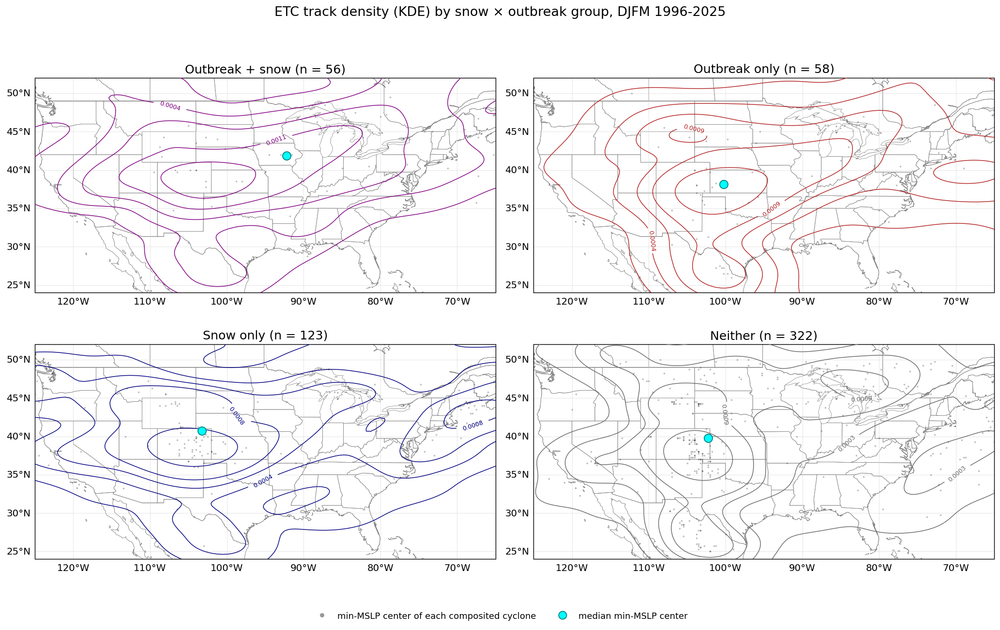

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), dpi=130,
                         subplot_kw={"projection": ccrs.PlateCarree()})

for ax, (g, (label, color)) in zip(axes.flat, GROUP_STYLE.items()):
    refs = picks_grp[picks_grp[COL_GROUP] == g]
    kde_map(ax, track_points(refs["track_id"]), refs, f"{label} (n = {len(refs)})", color)

handles = [Line2D([], [], marker="o", ls="none", ms=5, mfc="k", mec="none", alpha=0.4,
                  label="min-MSLP center of each composited cyclone"),
           Line2D([], [], marker="o", ls="none", ms=9, mfc="cyan", mec="teal",
                  label="median min-MSLP center")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, -0.01))
fig.suptitle("ETC track density (KDE) by snow × outbreak group, DJFM "
             f"{picks_grp['season_year'].min():.0f}-{picks_grp['season_year'].max():.0f}",
             fontsize=15)
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

## fig.savefig("Figs/snow_x_outbreak_track_density.png", dpi=300, bbox_inches="tight")


## Snow × outbreak composites (min-MSL reference time)
Top row: mean for each group. Bottom row: differences between groups
(permutation test + 5% FDR, same method as the OC vs NOC plots).


In [14]:
SNOW_DIR = "/data1/lepique/composites_snow_groups"

## group tag (file prefix from run_nodefilecompose_snow.sh) -> panel label
GROUP_LABELS = {
    "oc_snow":   "Outbreak + snow",
    "oc_only":   "Outbreak only",
    "snow_only": "Snow only",
    "neither":   "Neither",
}

## difference panels (A - B). Together these are the 2x2 factorial contrasts:
##   snow effect with / without an outbreak, outbreak effect with / without snow
COMPARISONS = [
    ("oc_snow",   "oc_only"),    # snow effect, given an outbreak
    ("snow_only", "neither"),    # snow effect, no outbreak
    ("oc_snow",   "snow_only"),  # outbreak effect, given snow
    ("oc_only",   "neither"),    # outbreak effect, no snow
]

G = 9.80665
K_to_F = lambda a: (a - 273.15) * 9/5 + 32

def load(group, stem, d=None):
    return xr.open_dataset(f"{d or SNOW_DIR}/{group}_min_msl_{stem}.nc", decode_times=False)

def field(stem, var, conv=lambda a: a):
    """Getter for a plain field: returns (composite mean, per-cyclone stack)."""
    def get(group, d=None):
        ds = load(group, stem, d)
        return conv(ds[var]), conv(ds[f"snap_{var}"]).values
    return get

def speed(ustem, uvar, vstem, vvar):
    """Getter for wind speed: speed of the mean vector (shaded) and per-cyclone
    speeds (tested) -- same convention as the OC/NOC wind plots."""
    def get(group, d=None):
        du, dv = load(group, ustem, d), load(group, vstem, d)
        mean = np.sqrt(du[uvar]**2 + dv[vvar]**2)
        snap = np.sqrt(du[f"snap_{uvar}"].values**2 + dv[f"snap_{vvar}"].values**2)
        return mean, snap
    return get

## black contour overlays: (stem, var, conversion, contour interval, label)
OVERLAYS = {
    "msl":  ("msl",  "msl",   lambda a: a / 100, 4,   "MSLP (hPa)"),
    "z850": ("z850", "z(5)",  lambda a: a / G,   30,  "850 hPa height (m)"),
    "z500": ("z500", "z(12)", lambda a: a / G,   60,  "500 hPa height (m)"),
    "z250": ("z250", "z(17)", lambda a: a / G,   120, "250 hPa height (m)"),
}


In [15]:
def plot_group_composites(title, get, levels, cmap, cbar_label, overlay="msl",
                          diff_get=None, diff_label="Δ", quiver=None, extend="both",
                          comp_dir=None, groups=GROUP_LABELS, comparisons=COMPARISONS,
                          n_resamples=5000, seed=1, alpha_fdr=0.1, nbins=10,
                          diff_fmt="%.1f", suptitle_tag="", diff_dir=None, savepath=False,
                          extra=None):
    """Top row: composite mean of each group (shaded) + overlay contours
    (+ optional mean-wind vectors). Bottom row: A - B for each comparison,
    FDR-significant points shaded, Δ contoured (plot_sig_panel).

    get      : getter(group, d) -> (mean 2-D, per-cyclone stack) for shading
    diff_get : optional getter used for the difference panels instead of get
               (e.g. shade 500 hPa vorticity but test 500 hPa height)
    quiver   : optional (ustem, uvar, vstem, vvar, scale, key) for vectors
    comp_dir : composite directory (defaults to SNOW_DIR); lets the
               MSLP-controlled composites reuse this function
    overlay: key into OVERLAYS for black contours, or None for no contours
    extra: optional fn(ax, group, comp_dir) drawing anything else on the top-row panels (e.g pv contours and jet)
    """
    diff_get = diff_get or get
    ncol = max(len(groups), len(comparisons))
    fig, axes = plt.subplots(2, ncol, figsize=(4.6 * ncol, 10.5), sharex=True, sharey=True)

    ## overlay levels shared across all groups so the contours are comparable
    if overlay is not None:
        ostem, ovar, oconv, oint, olabel = OVERLAYS[overlay]
        ov = {g: oconv(load(g, ostem, comp_dir)[ovar]) for g in groups}
        lo = min(float(o.min()) for o in ov.values())
        hi = max(float(o.max()) for o in ov.values())
        olevels = np.arange(np.floor(lo / oint) * oint, np.ceil(hi / oint) * oint + 1, oint)

    ## top row: group means
    for ax, (g, label) in zip(axes[0], groups.items()):
        mean, stack = get(g, comp_dir)
        x, y = mean["x"], mean["y"]
        cf = ax.contourf(x, y, mean, levels=levels, cmap=cmap, extend=extend)
        if overlay is not None:
            cs = ax.contour(x, y, ov[g], levels=olevels, colors="k", linewidths=0.6)
            ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
        if quiver is not None:
            ustem, uvar, vstem, vvar, scale, key = quiver
            u = load(g, ustem, comp_dir)[uvar]
            v = load(g, vstem, comp_dir)[vvar]
            q = ax.quiver(x[::3], y[::3], u[::3, ::3], v[::3, ::3],
                          scale=scale, width=0.003, color="black")
        if extra is not None:
            extra(ax, g, comp_dir)

        ax.axhline(0, color="gray", linewidth=0.4, linestyle="--")
        ax.axvline(0, color="gray", linewidth=0.4, linestyle="--")
        ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
        ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
        ax.set_title(f"{label} (n={stack.shape[0]})", fontsize=11)
    if quiver is not None:
        axes[0, -1].quiverkey(q, 0.85, 1.07, key, f"{key} m s$^{{-1}}$",
                              labelpos="E", fontproperties={"size": 8})

    ## bottom row: A - B with permutation test + BH-FDR
    for ax, (a, b) in zip(axes[1], comparisons):
        if diff_dir is None:
            _, sa = diff_get(a, comp_dir)
            _, sb = diff_get(b, comp_dir)
        else:
            _, sa = diff_get(f"{a}_vs_{b}__{a}", diff_dir)
            _, sb = diff_get(f"{a}_vs_{b}__{b}", diff_dir)

        diff_obs, pval = perm_test_diff_means(sa, sb, n_resamples=n_resamples, seed=seed)
        sig_fdr, p_fdr = bh_fdr(pval, alpha_fdr=alpha_fdr)
        print(f"{groups[a]} − {groups[b]}: p*={p_fdr:.4f}, "
              f"{int(np.nansum(sig_fdr))}/{int(np.isfinite(pval).sum())} significant")
        plot_sig_panel(ax, x, y, pval, diff_obs, sig_fdr, diff_fmt=diff_fmt, nbins=nbins)
        p_txt = "none significant" if not np.isfinite(p_fdr) else f"p* = {p_fdr:.4f}"
        n_txt = f"n={sa.shape[0]} vs {sb.shape[0]}; " if diff_dir else ""
        ax.set_title(f"{groups[a]} − {groups[b]}\n({n_txt}{p_txt}; contours: {diff_label})",
                     fontsize=10)

    ## hide unused panels if the two rows have different lengths
    for ax in list(axes[0, len(groups):]) + list(axes[1, len(comparisons):]):
        ax.set_visible(False)

    for ax in axes[:, 0]:
        ax.set_ylabel("Degrees from center (N +)", fontsize=9)

    fig.subplots_adjust(hspace=0.28, wspace=0.08, bottom=0.07, top=0.88)
    cbar = fig.colorbar(cf, ax=axes[0, :], orientation="horizontal",
                        pad=0.06, shrink=0.4, aspect=40)
    cbar.set_label(cbar_label if overlay is None else f"{cbar_label}  |  contours: {olabel}",
                   fontsize=10)

    fig.legend(handles=[mpatches.Patch(color=SIG_COLOR, alpha=SIG_ALPHA,
                                       label=f"FDR-significant ($\\alpha$={alpha_fdr})")],
               loc="lower center", frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f"{suptitle_tag}Cyclone-relative {title} composite — DJFM 1996-2025\n"
                 "Snow × outbreak groups (min-MSL ref.); permutation test + 10% FDR (Wilks 2016)",
                 fontsize=12, y=0.97)

    
    if savepath:
        plt.savefig(savepath, dpi=300)
    
    plt.show()

In [16]:
## PV advection by the irrotational wind (compute_irrotational.py)
## pvadv_chi = -V_chi . grad(PV), computed per time step before compositing.
## x1e6 -> PVU; x1e6 x86400 -> PVU day-1. 
PVU, PVU_DAY = 1e6, 1e6 * 86400

pvadv_levels = np.arange(-1.5, 1.51, 0.1)   # PVU day-1
pv_levels    = np.arange(1, 7, 1)           # PVU; 2 PVU (dynamic tropopause) bold
jet_levels   = [30, 35, 40, 45]             # m s-1

PVADV_LABEL = "$-\\mathbf{V}_\\chi \\cdot \\nabla PV$ (PVU day$^{-1}$)  |  vectors: V$_\\chi$"
PVJET_LABEL = PVADV_LABEL + "\nblack: PV (1 PVU interval, 2 PVU bold)  |  purple: 250 hPa jet (m s$^{-1}$)"

PVADV = field("pvadv_chi_l", "pvadv_chi_l", lambda a: a * PVU_DAY)   # shading
PV_L  = field("pv_l", "pv_l", lambda a: a * PVU)                     # tested in the overlay version
CHI_Q = ("uchi_l", "uchi_l", "vchi_l", "vchi_l", 60, 2)              # V_chi vectors, 2 m/s key

def pv_jet(ax, g, d=None):
    """extra= hook: 300-200 hPa PV contours (2 PVU bold) + 250 hPa jet."""
    pv  = load(g, "pv_l", d)["pv_l"] * PVU
    jet = np.sqrt(load(g, "u250", d)["u(17)"]**2 + load(g, "v250", d)["v(17)"]**2)
    cs = ax.contour(pv["x"], pv["y"], pv, levels=pv_levels, colors="k",
                    linewidths=[2.0 if l == 2 else 0.6 for l in pv_levels])
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
    cj = ax.contour(jet["x"], jet["y"], jet, levels=jet_levels, colors="darkviolet", linewidths=1.6)
    ax.clabel(cj, inline=True, fontsize=7, fmt="%.0f")


Outbreak + snow − Outbreak only: p*=0.0218, 2476/5668 significant
Snow only − Neither: p*=0.0088, 1069/6022 significant
Outbreak + snow − Snow only: p*=0.0046, 530/5730 significant
Outbreak only − Neither: p*=0.0236, 2862/6027 significant


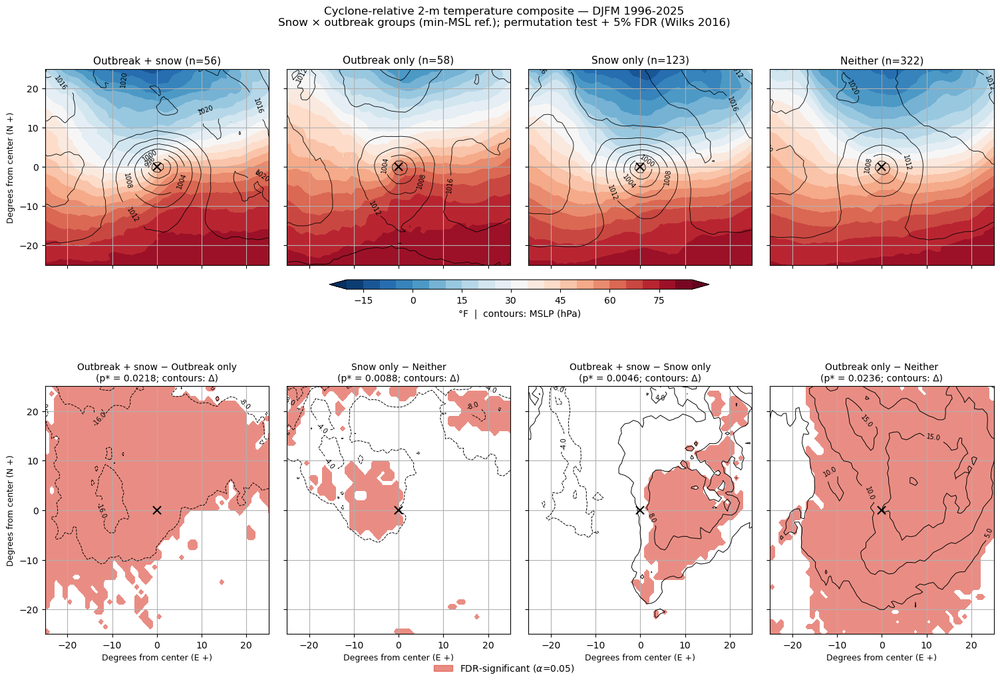

In [8]:
## 2-m temperature
plot_group_composites("2-m temperature", field("t2m", "t2m", K_to_F),
    levels=np.arange(-20, 86, 5), cmap="RdBu_r", cbar_label="°F")


Outbreak + snow − Outbreak only: p*=0.0162, 1850/5668 significant
Snow only − Neither: p*=0.0080, 973/6022 significant
Outbreak + snow − Snow only: p*=0.0018, 212/5730 significant
Outbreak only − Neither: p*=0.0150, 1812/6027 significant


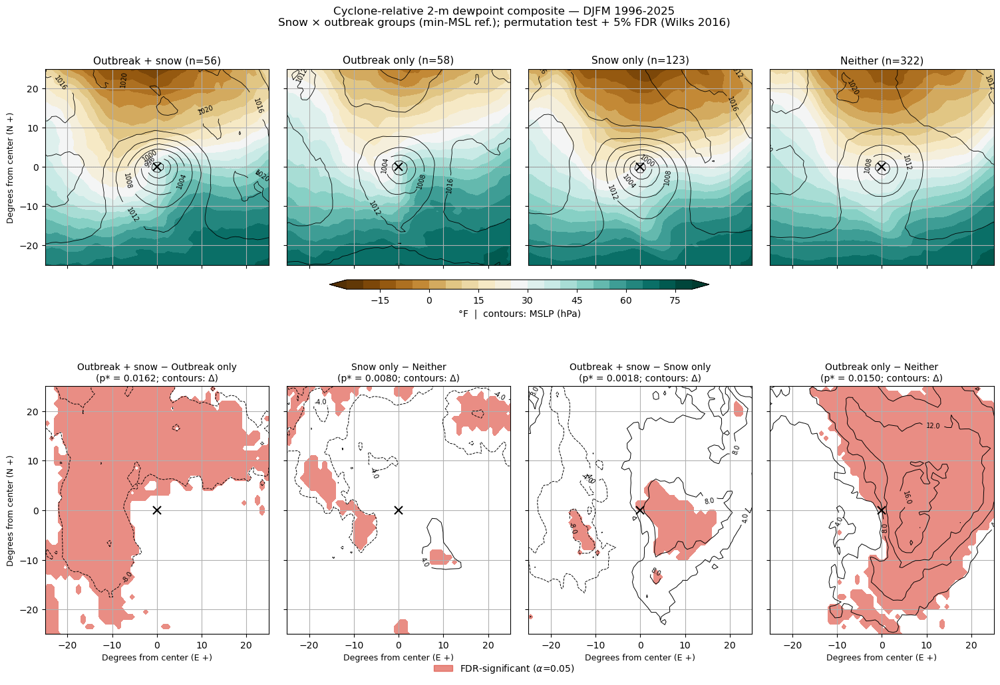

In [9]:
## 2-m dewpoint
plot_group_composites("2-m dewpoint", field("d2m", "d2m", K_to_F),
    levels=np.arange(-25, 81, 5), cmap="BrBG", cbar_label="°F")


Outbreak + snow − Outbreak only: p*=0.0124, 1418/5668 significant
Snow only − Neither: p*=0.0018, 219/6022 significant
Outbreak + snow − Snow only: p*=0.0008, 99/5730 significant
Outbreak only − Neither: p*=0.0088, 1065/6027 significant


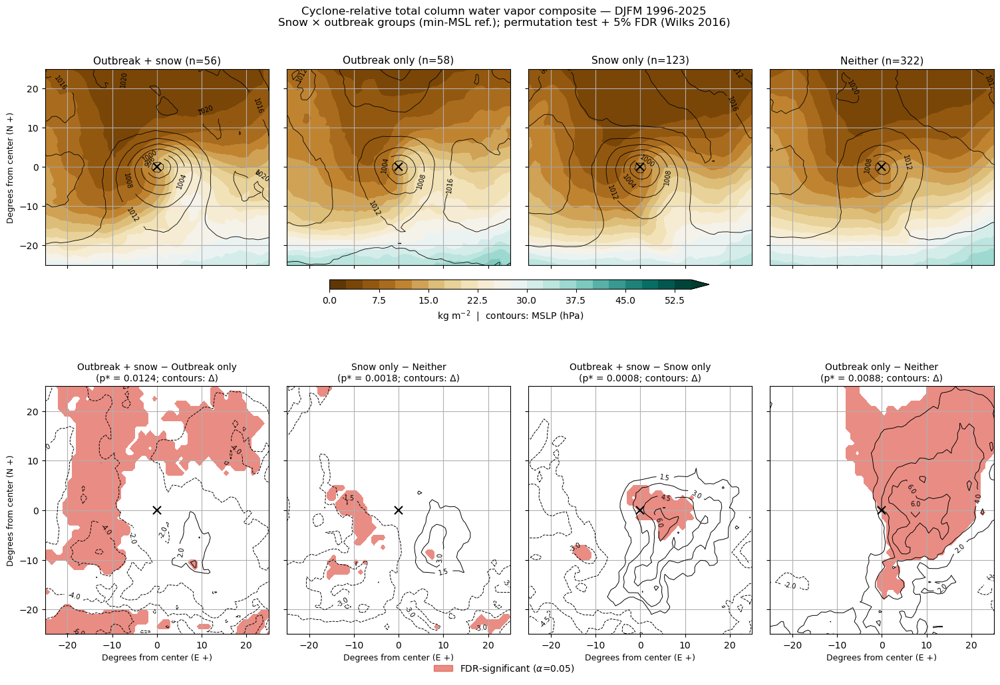

In [10]:
## total column water vapor
plot_group_composites("total column water vapor", field("tcwv", "tcwv"),
    levels=np.arange(0, 56, 2.5), cmap="BrBG", cbar_label="kg m$^{-2}$", extend="max")


Outbreak + snow − Outbreak only: p*=0.0178, 2027/5668 significant
Snow only − Neither: p*=0.0082, 993/6022 significant
Outbreak + snow − Snow only: p*=0.0002, 39/5730 significant
Outbreak only − Neither: p*=0.0132, 1598/6027 significant


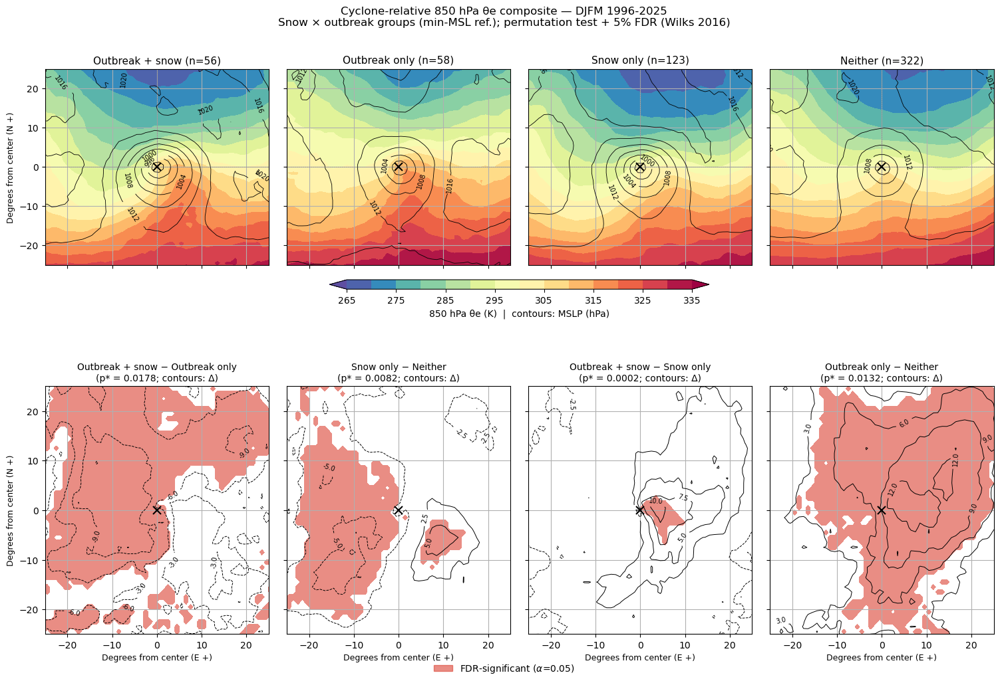

In [11]:
## 850 hPa theta-e
plot_group_composites("850 hPa θe", field("thetae850", "thetae(5)"),
    levels=np.arange(265, 336, 5), cmap="Spectral_r", cbar_label="850 hPa θe (K)")


Outbreak + snow − Outbreak only: p*=0.0042, 490/5668 significant
Snow only − Neither: p*=0.0044, 531/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=nan, 0/6027 significant


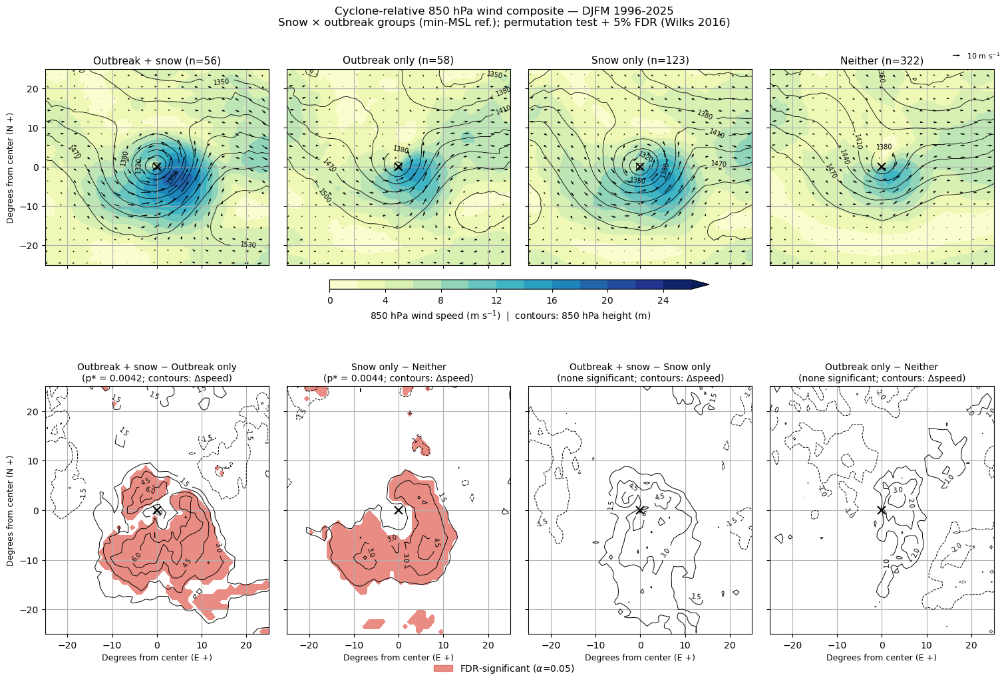

In [12]:
## 850 hPa wind
plot_group_composites("850 hPa wind", speed("u850", "u(5)", "v850", "v(5)"),
    levels=np.arange(0, 27, 2), cmap="YlGnBu", extend="max",
    cbar_label="850 hPa wind speed (m s$^{-1}$)", overlay="z850", diff_label="Δspeed",
    quiver=("u850", "u(5)", "v850", "v(5)", 300, 10))


Outbreak + snow − Outbreak only: p*=0.0014, 165/5668 significant
Snow only − Neither: p*=0.0062, 759/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=0.0006, 77/6027 significant


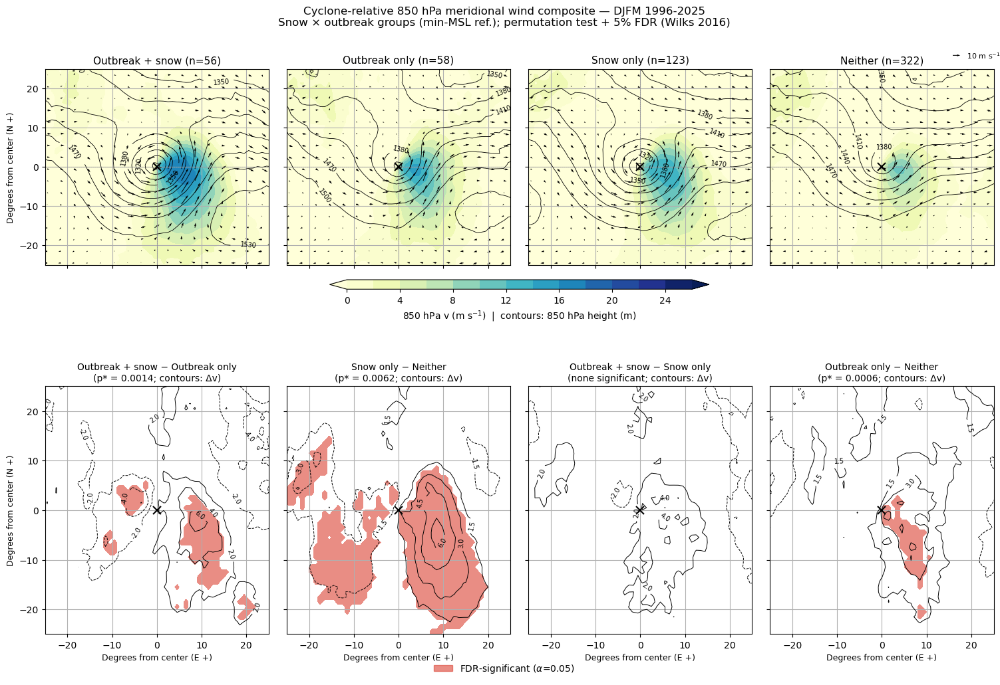

In [26]:
## 850 hPa meridional wind (signed, so diverging colormap centered on zero)
plot_group_composites("850 hPa meridional wind", field("v850", "v(5)"),
    levels=np.arange(0, 27, 2), cmap="YlGnBu",
    cbar_label="850 hPa v (m s$^{-1}$)", overlay="z850", diff_label="Δv",
    quiver=("u850", "u(5)", "v850", "v(5)", 300, 10))


Outbreak + snow − Outbreak only: p*=0.0102, 1165/5668 significant
Snow only − Neither: p*=0.0040, 485/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=0.0100, 1218/6027 significant


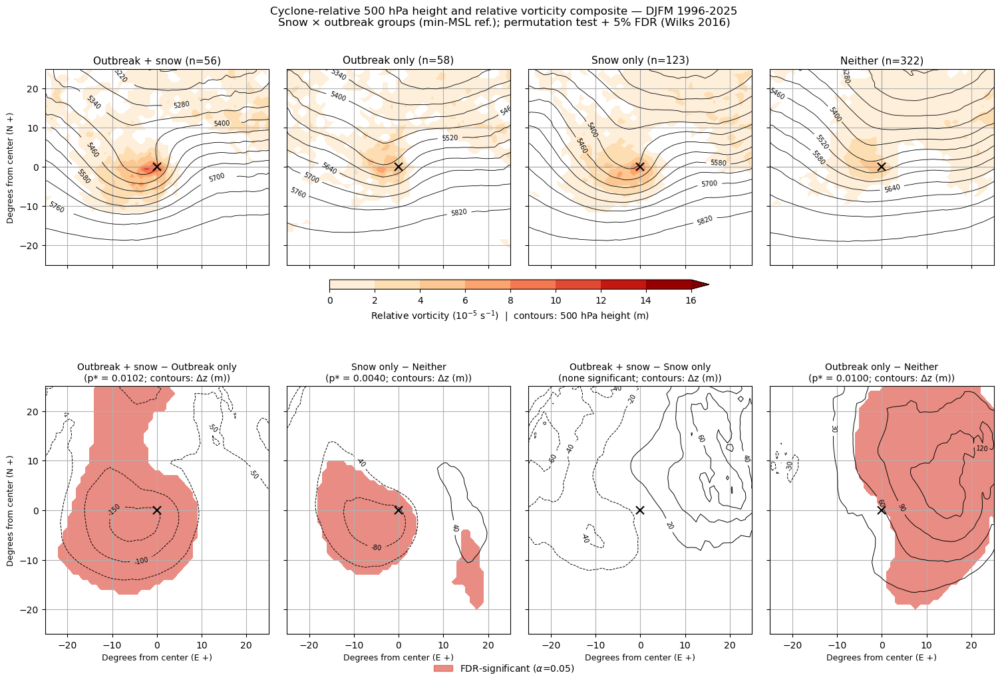

In [14]:
## 500 hPa: shade positive vorticity, test 500 hPa HEIGHT (as in the OC/NOC plot)
plot_group_composites("500 hPa height and relative vorticity",
    field("vo500", "vo(12)", lambda a: (a * 1e5).where(a > 0)),
    levels=np.arange(0, 17, 2), cmap="OrRd", extend="max",
    cbar_label="Relative vorticity (10$^{-5}$ s$^{-1}$)", overlay="z500",
    diff_get=field("z500", "z(12)", lambda a: a / G), diff_label="Δz (m)", diff_fmt="%.0f")


Outbreak + snow − Outbreak only: p*=0.0026, 304/5668 significant
Snow only − Neither: p*=0.0038, 460/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=0.0010, 129/6027 significant


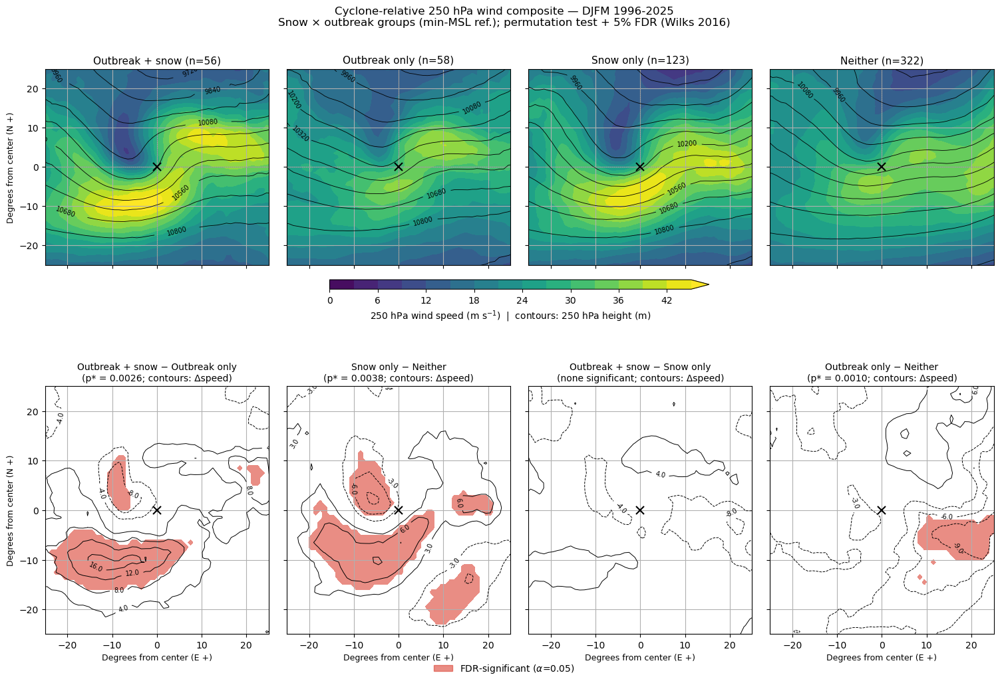

In [22]:
## 250 hPa wind
plot_group_composites("250 hPa wind", speed("u250", "u(17)", "v250", "v(17)"),
    levels=np.arange(0, 46, 3), cmap="viridis", extend="max",
    cbar_label="250 hPa wind speed (m s$^{-1}$)", overlay="z250", diff_label="Δspeed",
    savepath='snowfall_x_scs_250.png')


Outbreak + snow − Outbreak only: p*=nan, 0/5668 significant
Snow only − Neither: p*=nan, 0/6022 significant
Outbreak + snow − Snow only: p*=0.0002, 28/5730 significant
Outbreak only − Neither: p*=0.0030, 367/6027 significant


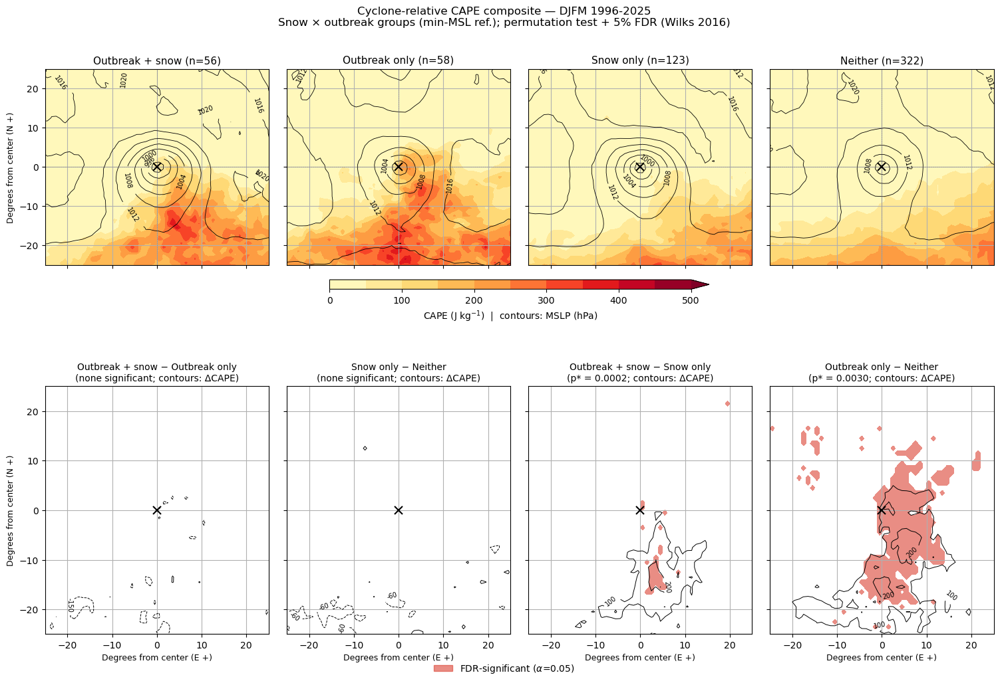

In [16]:
## CAPE
plot_group_composites("CAPE", field("cape", "cape"),
    levels=np.arange(0, 501, 50), cmap="YlOrRd", extend="max",
    cbar_label="CAPE (J kg$^{-1}$)", diff_label="ΔCAPE", diff_fmt="%.0f")


Outbreak + snow − Outbreak only: p*=0.0036, 419/5668 significant
Snow only − Neither: p*=0.0024, 307/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=0.0052, 630/6027 significant


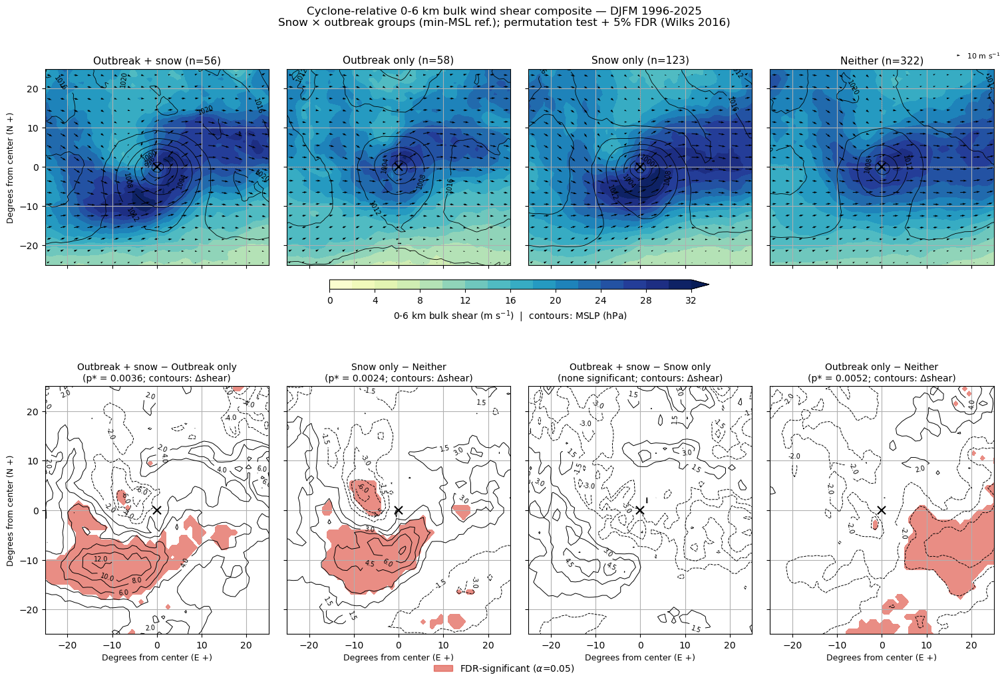

Outbreak + snow − Outbreak only: p*=0.0026, 299/5668 significant
Snow only − Neither: p*=0.0022, 281/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=0.0042, 514/6027 significant


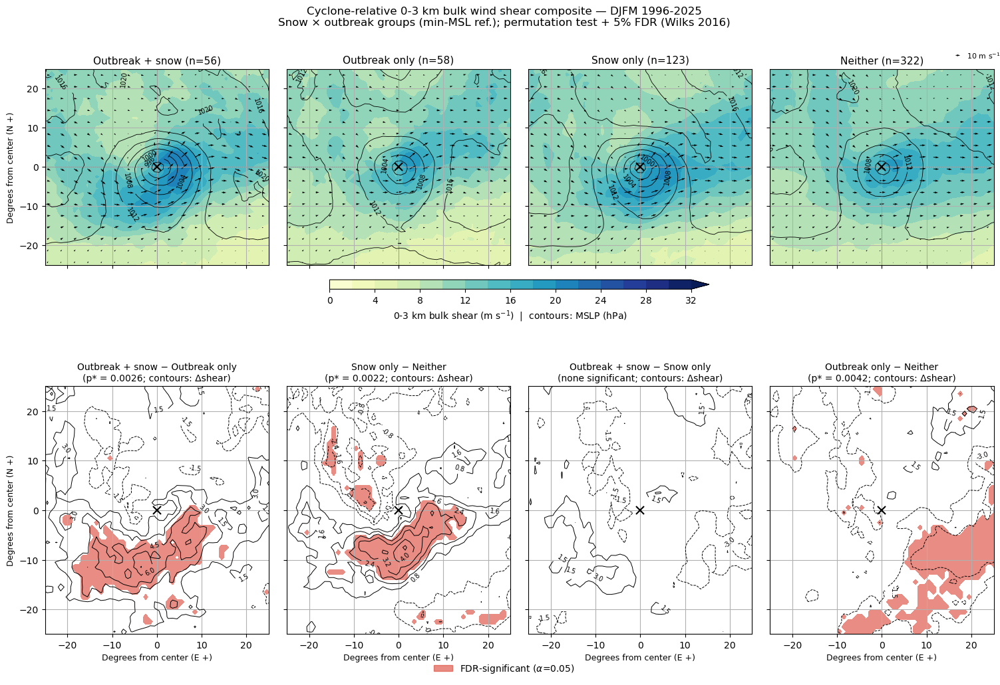

Outbreak + snow − Outbreak only: p*=0.0004, 57/5668 significant
Snow only − Neither: p*=0.0028, 342/6022 significant
Outbreak + snow − Snow only: p*=nan, 0/5730 significant
Outbreak only − Neither: p*=nan, 0/6027 significant


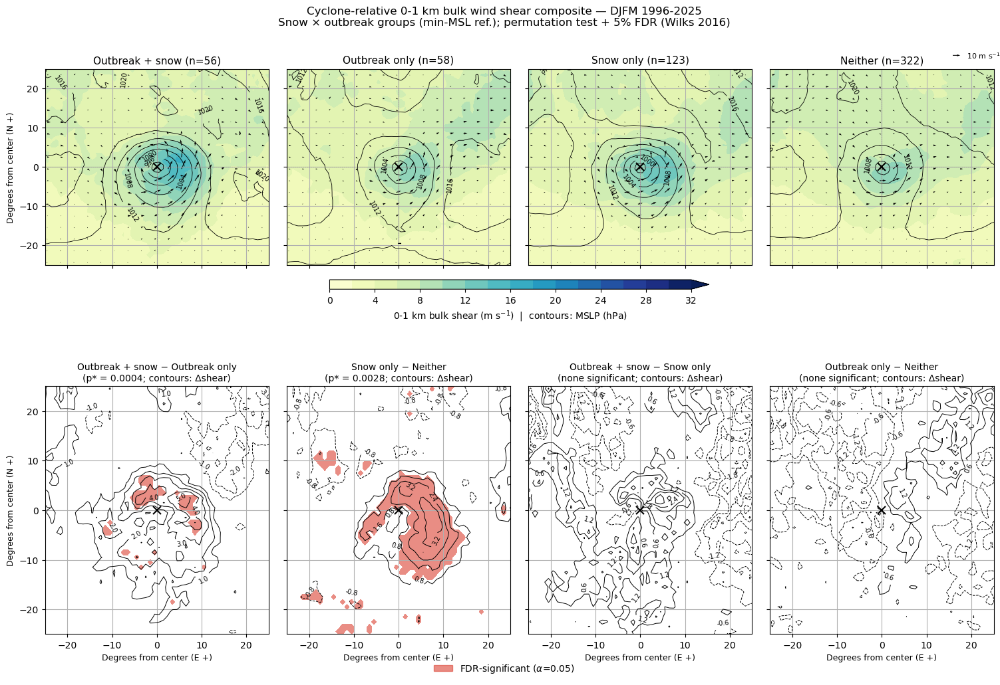

In [17]:
## bulk shear (0-6, 0-3, 0-1 km)
for tag, label, scale in [("shear06", "0-6 km", 700), ("shear03", "0-3 km", 500),
                          ("shear01", "0-1 km", 300)]:
    plot_group_composites(f"{label} bulk wind shear", field(tag, tag),
        levels=np.arange(0, 33, 2), cmap="YlGnBu", extend="max",
        cbar_label=f"{label} bulk shear (m s$^{{-1}}$)", diff_label="Δshear", nbins=14,
        quiver=(f"{tag}_u", f"{tag}_u", f"{tag}_v", f"{tag}_v", scale, 10))


## SCS X Snowfall Composites: Controlling for Intensity and Seasonality 
#### This is done by matching each cyclone from each target group group to a cyclone from the NEITHER category, from the same month and of similar intensity

In [11]:
## Month + intensity control against the neither population: each cyclone in a 
## target group is paired with a NEITHER cyclone from the same calendar month
## with the closest min_msl. Within each month, linear_sum_assignment pairs the cyclones so that
## the total min_msl difference is as small as possible. Pairs more than MSL_CALIPER hPa apart are 
## dropped, which trims the deepest target cyclones that simply have no close match. This is a limitation. 
## Each target group gets its own NEITHER controls (the same neither cyclone can appear in more than one 
## groups control). 

TARGET_GROUPS = ["OC_SNOW", "OC_ONLY", "SNOW_ONLY"]
CONTROL_GROUP = "NEITHER"
MSL_CALIPER = 5.0  ## hpa 

In [19]:
picks_grp["min_msl"] = picks_grp["track_id"].map(etc_summary.set_index("track_id")["min_msl"])
picks_grp["ref_month"] = picks_grp[REF_TIME_COL].dt.month
neither_pool = picks_grp[picks_grp[COL_GROUP] == CONTROL_GROUP]

matched_vs_neither = {}
for g in TARGET_GROUPS:
    grp = picks_grp[picks_grp[COL_GROUP] == g]
    ig, ic = [], []
    for m in MONTHS:
        Gm = grp[grp["ref_month"] == m]
        Cm = neither_pool[neither_pool["ref_month"] == m]
        if len(Gm) > len(Cm):
            raise ValueError(f"{g}: {len(Gm)} cyclones but only {len(Cm)} NEITHER in month {m}")
        cost = np.abs(Gm["min_msl"].values[:, None] - Cm["min_msl"].values[None, :])
        r, c = linear_sum_assignment(cost)
        keep = cost[r, c] <= MSL_CALIPER
        ig.extend(Gm.index[r[keep]])
        ic.extend(Cm.index[c[keep]])
    mg, mc = grp.loc[ig], neither_pool.loc[ic]
    matched_vs_neither[g] = (mg, mc)

    res = permutation_test((mg["min_msl"].values, mc["min_msl"].values), mean_diff,
                           permutation_type="independent", n_resamples=10000,
                           alternative="two-sided", random_state=1)
    months = "/".join(str(int((mg["ref_month"] == m).sum())) for m in MONTHS)
    print(f"{g:9s}: kept {len(mg):3d}/{len(grp)}  min_msl gap vs all NEITHER "
          f"{grp['min_msl'].mean() - neither_pool['min_msl'].mean():+.2f} -> matched "
          f"{res.statistic:+.2f} hPa (p={res.pvalue:.3f})  months D/J/F/M {months}")

OC_SNOW  : kept  42/56  min_msl gap vs all NEITHER -12.35 -> matched -0.96 hPa (p=0.612)  months D/J/F/M 6/7/12/17
OC_ONLY  : kept  52/58  min_msl gap vs all NEITHER -4.31 -> matched -0.44 hPa (p=0.749)  months D/J/F/M 3/6/3/40
SNOW_ONLY: kept  98/123  min_msl gap vs all NEITHER -8.80 -> matched -0.72 hPa (p=0.527)  months D/J/F/M 29/24/22/23


In [20]:
matched_vs_neither.items()

dict_items([('OC_SNOW', (     track_id  grid_i  grid_j  year  month  day offset     lon    lat  \
242    2716.0    1171     173  2008     12   12     19  292.75  46.75   
263    2926.0    1062     192  2009     12   25     19  265.50  42.00   
316    3530.0    1147     180  2012     12   21     23  286.75  45.00   
335    3728.0    1073     224  2013     12   21     21  268.25  34.00   
378    4143.0    1080     206  2015     12   28     20  270.00  38.50   
431    4763.0    1060     201  2018     12    1     19  265.00  39.75   
23      228.0    1123     171  1997      1    5     20  280.75  47.25   
42      452.0    1092     211  1998      1    8      9  273.00  37.25   
110    1076.0    1014     238  2001      1   27     21  253.50  30.50   
381    4156.0    1171     203  2016      1   23     22  292.75  39.25   
508    5642.0    1002     201  2023      1    2     10  250.50  39.75   
509    5649.0    1164     179  2023      1   13     19  291.00  45.25   
527    5849.0    1111     

In [28]:
### write the nodefiles (six files, two per group)
for g, (mg, mc) in matched_vs_neither.items():
    for side, df in ((g, mg), (CONTROL_GROUP, mc)):
        tag = f"{g}_vs_{CONTROL_GROUP}__{side}".lower()
        write_snapshot_nodefile(df, f"../data/snowgrp_vsneither_{tag}.txt", NODE_DATA_COLS)

 wrote 42 -> ../data/snowgrp_vsneither_oc_snow_vs_neither__oc_snow.txt
 wrote 42 -> ../data/snowgrp_vsneither_oc_snow_vs_neither__neither.txt
 wrote 52 -> ../data/snowgrp_vsneither_oc_only_vs_neither__oc_only.txt
 wrote 52 -> ../data/snowgrp_vsneither_oc_only_vs_neither__neither.txt
 wrote 98 -> ../data/snowgrp_vsneither_snow_only_vs_neither__snow_only.txt
 wrote 98 -> ../data/snowgrp_vsneither_snow_only_vs_neither__neither.txt


In [12]:
VSNEITHER_DIR = "/data1/lepique/composites_snow_groups_vsneither"
VS_NEITHER = [("oc_snow", "neither"), ("oc_only", "neither"), ("snow_only", "neither")]


Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=0.0184, 1067/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


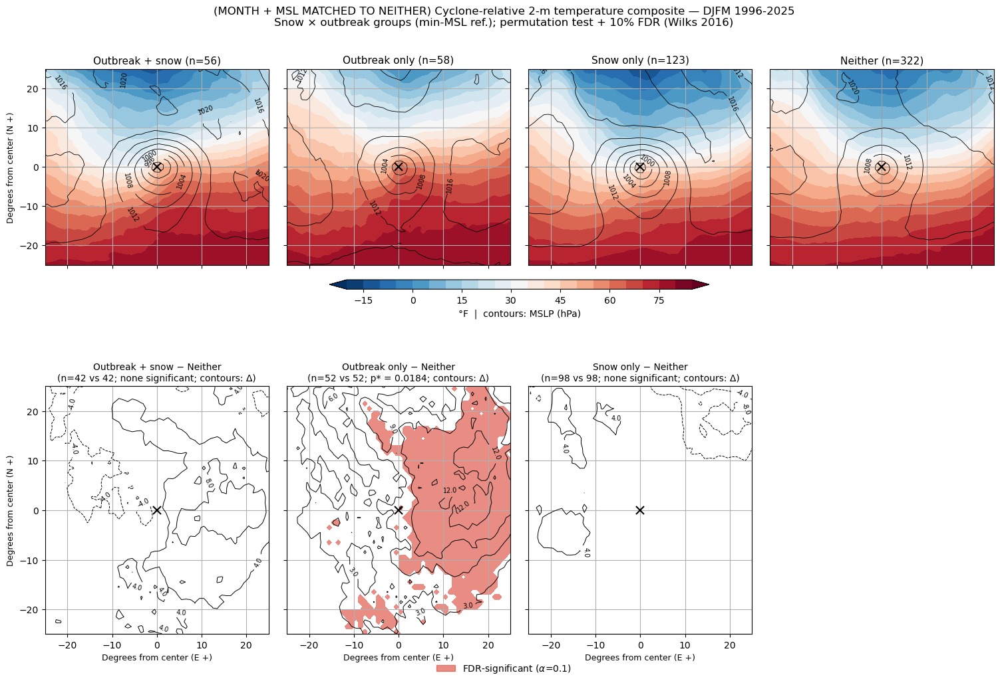

In [22]:
plot_group_composites("2-m temperature", field("t2m", "t2m", K_to_F),
    levels=np.arange(-20, 86, 5), cmap="RdBu_r", cbar_label="°F",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=0.0010, 57/5560 significant
Outbreak only − Neither: p*=0.0198, 1150/5778 significant
Snow only − Neither: p*=0.0038, 232/5966 significant


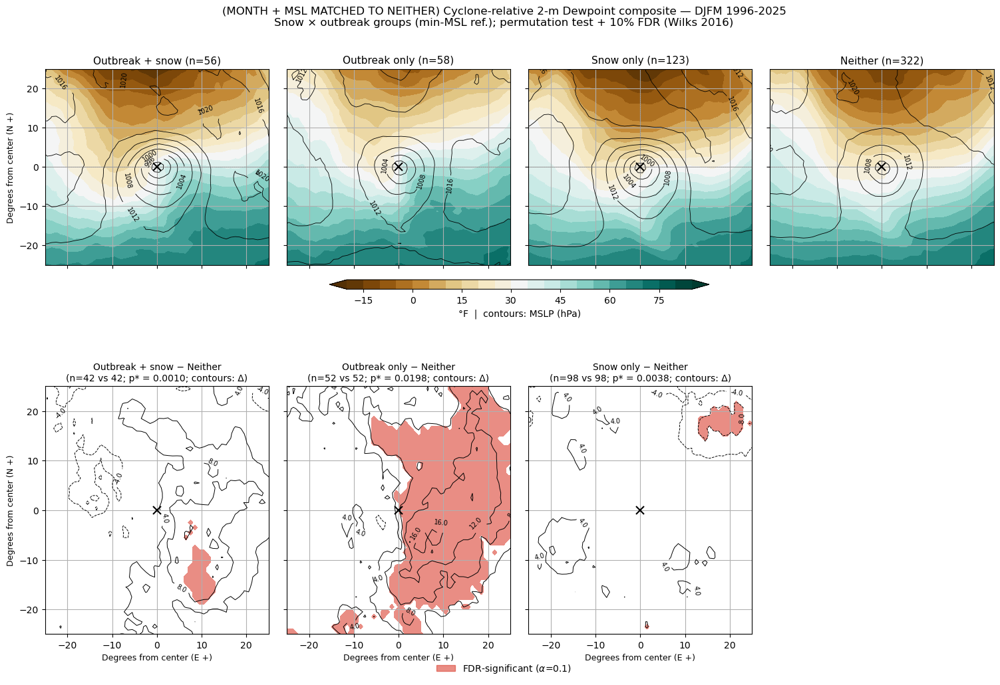

In [23]:
plot_group_composites("2-m Dewpoint", field("d2m", "d2m", K_to_F),
    levels=np.arange(-20, 86, 5), cmap="BrBG", cbar_label="°F",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=0.0150, 869/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


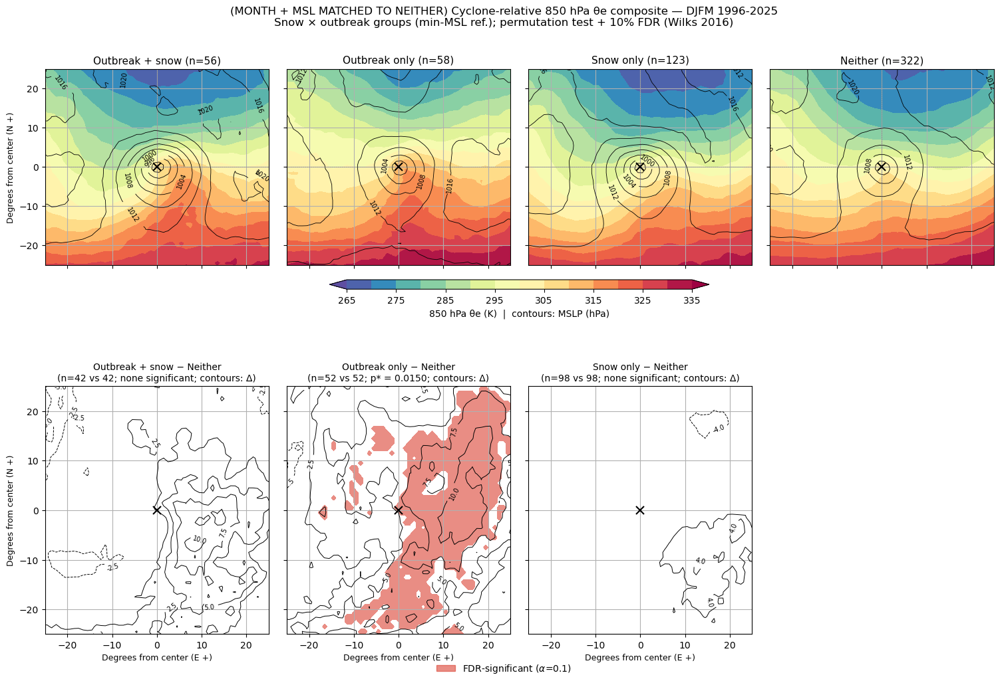

In [24]:
plot_group_composites("850 hPa θe", field("thetae850", "thetae(5)"),
    levels=np.arange(265, 336, 5), cmap="Spectral_r", cbar_label="850 hPa θe (K)",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=nan, 0/5778 significant
Snow only − Neither: p*=0.0002, 12/5966 significant


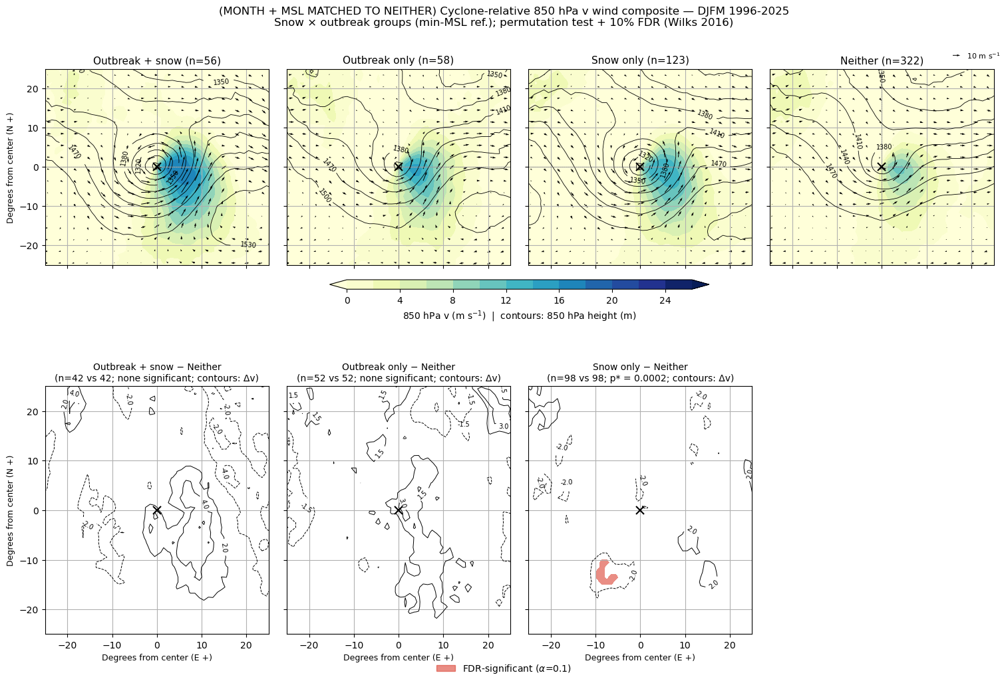

In [25]:
plot_group_composites("850 hPa v wind", field("v850", "v(5)"),
    levels=np.arange(0, 27, 2), cmap="YlGnBu", cbar_label="850 hPa v (m s$^{-1}$)",
    overlay="z850", diff_label="Δv", quiver=("u850", "u(5)", "v850", "v(5)", 300, 10),
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=0.0058, 328/5560 significant
Outbreak only − Neither: p*=0.0118, 685/5778 significant
Snow only − Neither: p*=0.0070, 424/5966 significant


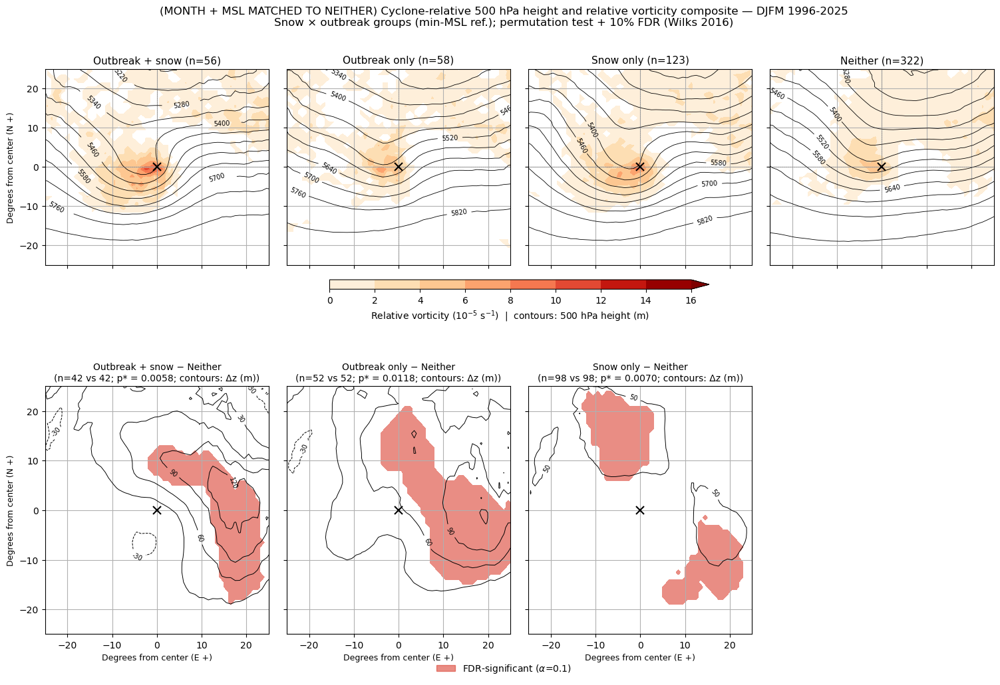

In [26]:
plot_group_composites("500 hPa height and relative vorticity",
    field("vo500", "vo(12)", lambda a: (a * 1e5).where(a > 0)),
    levels=np.arange(0, 17, 2), cmap="OrRd", extend="max",
    cbar_label="Relative vorticity (10$^{-5}$ s$^{-1}$)", overlay="z500",
    diff_get=field("z500", "z(12)", lambda a: a / G), diff_label="Δz (m)", diff_fmt="%.0f",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=nan, 0/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


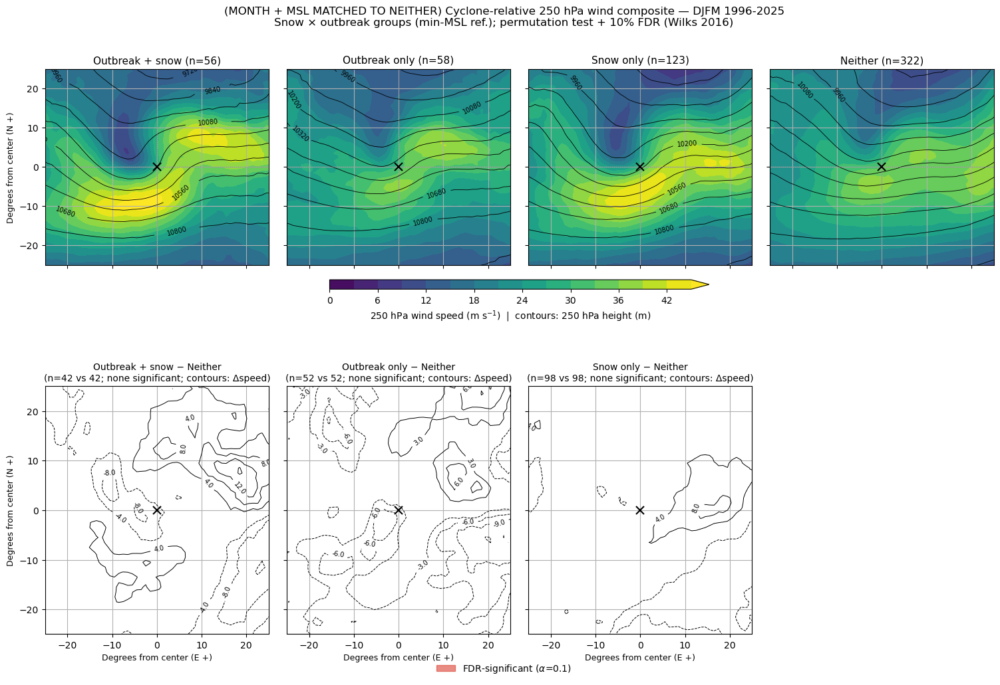

In [27]:
## 250 hPa wind
plot_group_composites("250 hPa wind", speed("u250", "u(17)", "v250", "v(17)"),
    levels=np.arange(0, 46, 3), cmap="viridis", extend="max",
    cbar_label="250 hPa wind speed (m s$^{-1}$)", overlay="z250", diff_label="Δspeed",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=nan, 0/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


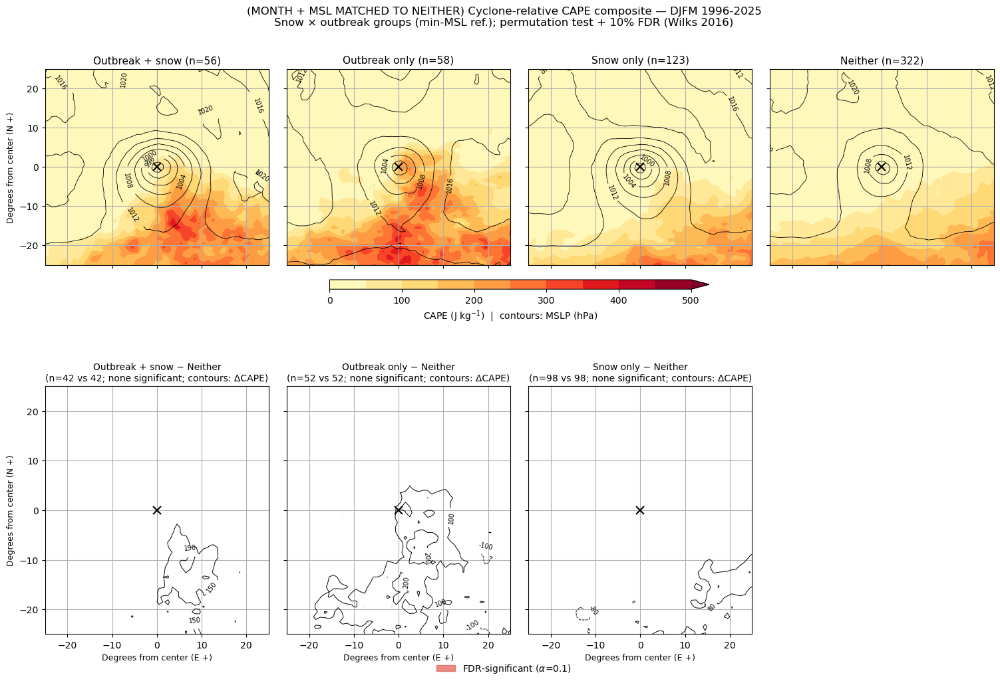

In [17]:
## CAPE
plot_group_composites("CAPE", field("cape", "cape"),
    levels=np.arange(0, 501, 50), cmap="YlOrRd", extend="max",
    cbar_label="CAPE (J kg$^{-1}$)", diff_label="ΔCAPE", diff_fmt="%.0f",
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=0.0112, 649/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


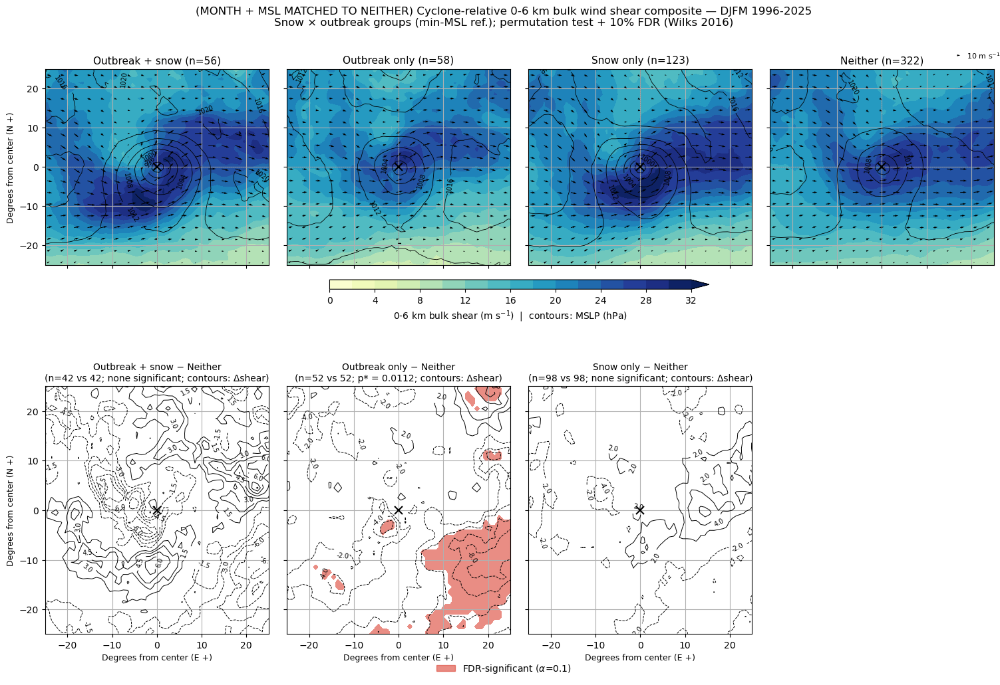

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=0.0046, 269/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


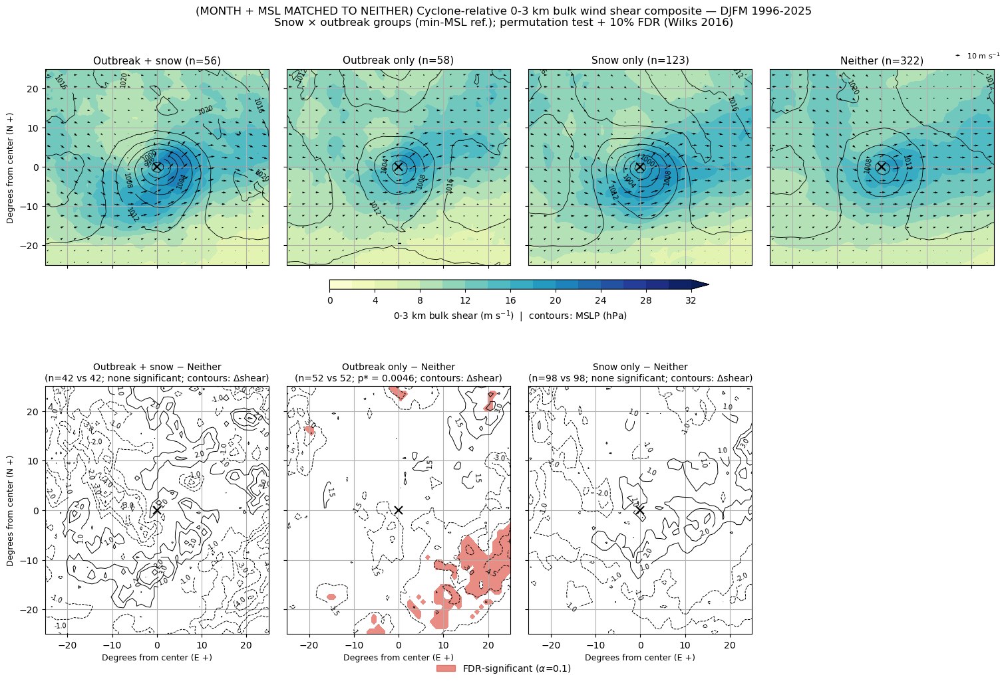

Outbreak + snow − Neither: p*=nan, 0/5560 significant
Outbreak only − Neither: p*=nan, 0/5778 significant
Snow only − Neither: p*=nan, 0/5966 significant


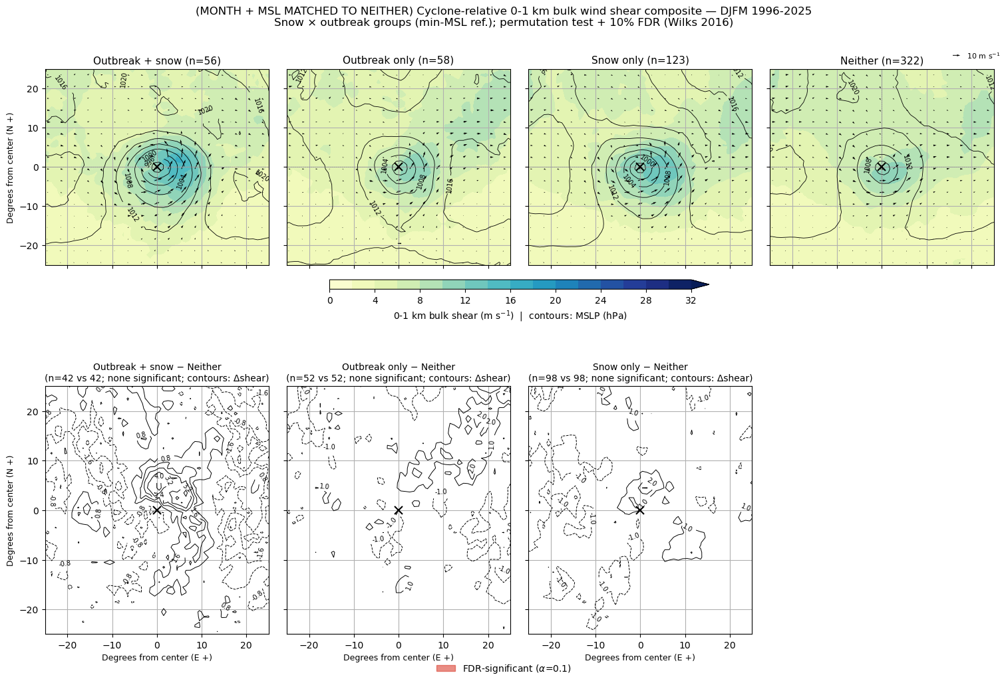

In [29]:
## bulk shear (0-6, 0-3, 0-1 km)
for tag, label, scale in [("shear06", "0-6 km", 700), ("shear03", "0-3 km", 500),
                          ("shear01", "0-1 km", 300)]:
    plot_group_composites(f"{label} bulk wind shear", field(tag, tag),
        levels=np.arange(0, 33, 2), cmap="YlGnBu", extend="max",
        cbar_label=f"{label} bulk shear (m s$^{{-1}}$)", diff_label="Δshear", nbins=14,
        quiver=(f"{tag}_u", f"{tag}_u", f"{tag}_v", f"{tag}_v", scale, 10),
        comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
        suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")


Outbreak + snow − Neither: p*=nan, 0/6400 significant
Outbreak only − Neither: p*=nan, 0/6400 significant
Snow only − Neither: p*=nan, 0/6400 significant


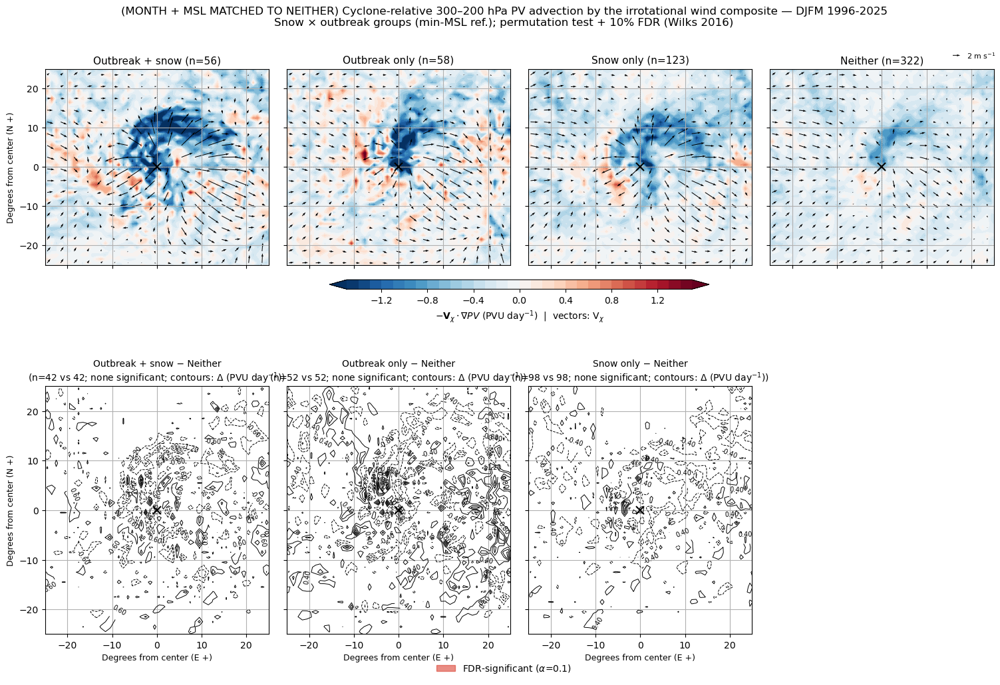

In [18]:
plot_group_composites("300–200 hPa PV advection by the irrotational wind", PVADV,
    levels=pvadv_levels, cmap="RdBu_r", cbar_label=PVADV_LABEL, overlay=None,
    quiver=CHI_Q, diff_label="Δ (PVU day$^{-1}$)", diff_fmt="%.2f", nbins=12,
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")

Outbreak + snow − Neither: p*=nan, 0/6400 significant
Outbreak only − Neither: p*=nan, 0/6400 significant
Snow only − Neither: p*=nan, 0/6400 significant


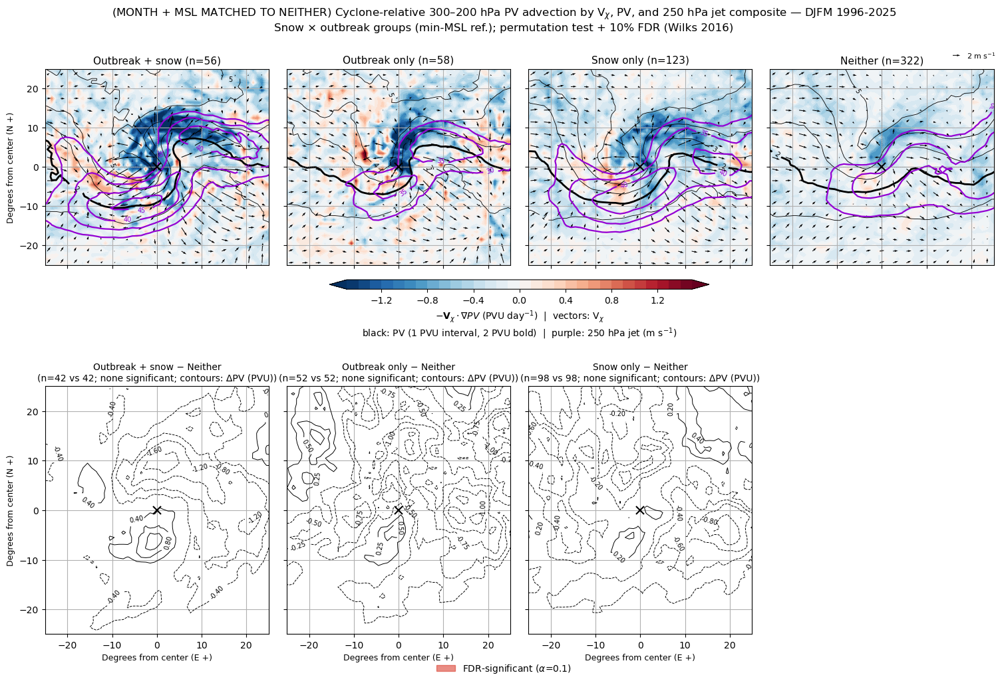

In [19]:
plot_group_composites("300–200 hPa PV advection by V$_\\chi$, PV, and 250 hPa jet", PVADV,
    levels=pvadv_levels, cmap="RdBu_r", cbar_label=PVJET_LABEL, overlay=None,
    quiver=CHI_Q, extra=pv_jet, diff_get=PV_L, diff_label="ΔPV (PVU)", diff_fmt="%.2f", nbins=12,
    comparisons=VS_NEITHER, diff_dir=VSNEITHER_DIR,
    suptitle_tag="(MONTH + MSL MATCHED TO NEITHER) ")